<a href="https://colab.research.google.com/github/DanisStepanov/image_processing/blob/main/%D0%9F%D1%80%D0%BE%D0%B5%D0%BA%D1%82%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%964_%D0%90%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D0%B4%D0%B8%D0%BD%D0%B0%D0%BC%D0%B8%D0%BA%D0%B8_%D0%B8%D0%B7%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B9_%D0%B7%D0%B5%D0%BC%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BF%D0%BE%D0%BA%D1%80%D0%BE%D0%B2%D0%B0_%D0%BD%D0%B0_%D0%BF%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D1%80%D0%B0%D0%B7%D0%BD%D0%BE%D0%B2%D1%80%D0%B5%D0%BC%D0%B5%D0%BD%D0%BD%D1%8B%D1%85_%D1%81%D0%BD%D0%B8%D0%BC%D0%BA%D0%BE%D0%B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Проектная работа №4. Анализ динамики изменений земного покрова на последовательности разновременных спутниковых смимков с использованием спектральных индексов**

## **1. Цель работы**

Выполнить количественный анализ динамики изменения классов земного покрова на выбранной территории за период с 2017 по 2024 год на основе разновременных спутниковых снимков Sentinel-2 и провести сравнительную оценку результатов, полученных методом пороговой сегментации на основе спектральных индексов и с использованием готовых карт классификации Dynamic World.

## **2. Задачи работы**

1.  **Подготовить** последовательность разновременных снимков (снимки Sentinel-2 и карты Dynamic World) за 2017-2024 гг.;
2.  **Классифицировать** земной покров на снимках Sentinel-2, применив метод пороговой сегментации по спектральным индексам;
3.  **Рассчитать и сравнить** количественные показатели динамики (площади, темпы роста) для двух методов классификации: по индексам и по данным Dynamic World;
4.  **Оценить** выявленные тренды изменения покрова и **сформулировать** выводы о сопоставимости результатов двух методов анализа.

## **3. Загрузка данных для анализа из Google Earth Engine**

> **Примечание.** В качестве примера реализации можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/nWdJIg. Для выполнения текущей работы актуальны только **Раздел 1** и **Раздел 2** указанного источника.





### **3.1. Настройка рабочей среды и аутентификация**

In [2]:
%%capture
!pip install -U "geemap[workshop]"

In [3]:
import ee
import geemap

import os
import numpy as np
import pandas as pd
import rasterio
import rasterio.plot
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [4]:
ee.Authenticate()
ee.Initialize(project='cedar-bot-510810-r8') # Тут должно быть имя Вашего проекта

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


### **3.2. Определение области интереса**

- Выберите территорию размером не менее 10×10 км (100 км²) с разнообразным земным покровом
- Обязательно должны присутствовать: водные объекты, растительность, застройка, открытая почва
- Зафиксируйте координаты углов ROI для воспроизводимости результатов

In [5]:
# 3.2. Определение области интереса (ROI)
# Теория: Т2, Раздел 1.4, яч. 20 (#scrollTo=dcf02117) и яч. 22 (#scrollTo=a7f280fd)

# Создание интерактивной карты с центром на выбранной территории
Map = geemap.Map(center=[55.895, 37.49], zoom=11)
Map.add_basemap('Esri.WorldTopoMap')
Map.add_draw_control()   # инструменты рисования -> Map.user_roi

# Координаты углов ROI зафиксированы для воспроизводимости результатов
# (долгота, широта), формат [[долгота, широта], ...]
roi_corners = [
    [37.40, 55.83],   # юго-запад
    [37.58, 55.83],   # юго-восток
    [37.58, 55.96],   # северо-восток
    [37.40, 55.96],   # северо-запад
    [37.40, 55.83],   # замыкание контура
]


def get_user_roi():
    """
    Извлекает пользовательскую область интереса из интерактивной карты.
    Если область не нарисована, возвращает предустановленный полигон.

    Возвращает:
        ee.Geometry: объект геометрии для использования в анализе
    """
    if Map.user_roi is not None:
        # Возвращаем нарисованную пользователем область
        return Map.user_roi
    else:
        # Создаем полигон по умолчанию (северо-запад Москвы и окрестности)
        default_roi = ee.Geometry.Polygon([roi_corners])
        return default_roi


# Получение и визуализация области интереса
roi = get_user_roi()

map_roi = geemap.Map(zoom=11)
map_roi.add_basemap('Esri.WorldTopoMap')
map_roi.centerObject(roi, 11)
map_roi.addLayer(roi, {'color': 'red'}, 'Область интереса')

# Проверка соответствия требованию "не менее 10x10 км"
roi_area_km2 = roi.area(1).getInfo() / 1e6
print(f"Углы ROI (долгота, широта): {roi_corners}")
print(f"Площадь ROI: {roi_area_km2:.2f} км²")
map_roi

Углы ROI (долгота, широта): [[37.4, 55.83], [37.58, 55.83], [37.58, 55.96], [37.4, 55.96], [37.4, 55.83]]
Площадь ROI: 162.23 км²


Map(center=[55.89499651986688, 37.49000000000015], controls=(WidgetControl(options=['position', 'transparent_b…

### **3.3. Функции для загрузки и обработки данных Sentinel-2**

In [35]:
bands = ['B2', 'B3', 'B4', 'B8', 'B11']
def load_sentinel2_collection(roi, start_date, end_date, cloud_percentage=20,
                              bands=bands):
    collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    collection = collection.filterBounds(roi)
    collection = collection.filterDate(start_date, end_date)

    collection = collection.filter(
        ee.Filter.lessThan('CLOUDY_PIXEL_PERCENTAGE', cloud_percentage)
    )
    def mask_clouds(image):
        qa = image.select('QA60')
        cloud_bit_mask = 1 << 10
        cirrus_bit_mask = 1 << 11

        mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(
            qa.bitwiseAnd(cirrus_bit_mask).eq(0)
        )
        return image.updateMask(mask).divide(10000).copyProperties(
            image, ['system:time_start']
        )
    return collection.map(mask_clouds).select(bands)
def create_median_composite(collection, roi):
    median_image = collection.median()
    median_image = median_image.clip(roi)
    return median_image

### **3.4. Создание медианных композитов за летние периоды 2019-2024**

- Используйте медиану для минимизации влияния облачности
- Фильтрация по облачности: CLOUDY_PIXEL_PERCENTAGE < 20%


In [8]:
# 3.4. Создание медианных композитов за летние периоды (июнь-август)
# Теория: Т2, яч. 35 (#scrollTo=64fa44fe) и яч. 39 (#scrollTo=8W0RlyBeyWjO)
years = list(range(2017, 2025))
composites = {}

for year in years:
    # Летний период: июнь - август (end_date не включается)
    start_date = f'{year}-06-01'
    end_date = f'{year}-09-01'

    # Фильтрация по облачности: CLOUDY_PIXEL_PERCENTAGE < 20%
    sentinel_collection = load_sentinel2_collection(roi, start_date, end_date, 20)
    n_images = sentinel_collection.size().getInfo()

    # Если за лето не прошло ни один снимок - ослабляем порог облачности
    if n_images == 0:
        sentinel_collection = load_sentinel2_collection(roi, start_date, end_date, 40)
        n_images = sentinel_collection.size().getInfo()
        print(f"{year}: снимков с облачностью <20% нет, взят порог 40%")

    print(f"{year}: найдено снимков - {n_images}")

    median_composite = create_median_composite(sentinel_collection, roi)
    composites[year] = median_composite

# Параметры визуализации для естественных цветов (RGB) - Т2, яч. 39
vis_params = {
    'bands': ['B4', 'B3', 'B2'],  # Красный, зеленый, синий каналы
    'min': 0.0,
    'max': 0.3,
    'gamma': 1.4
}

map_composite = geemap.Map()
map_composite.add_basemap('Esri.WorldTopoMap')
map_composite.centerObject(roi, 11)
map_composite.addLayer(composites[2024], vis_params, 'Медианный композит RGB 2024')
map_composite

2017: найдено снимков - 3
2018: найдено снимков - 2
2019: найдено снимков - 36
2020: найдено снимков - 19
2021: найдено снимков - 55
2022: найдено снимков - 27
2023: найдено снимков - 23
2024: найдено снимков - 41


Map(center=[55.89499651986688, 37.49000000000015], controls=(WidgetControl(options=['position', 'transparent_b…

### **3.5. Функции для загрузки и обработки данных карт классификации**

**Используйте коллекцию Dynamic World (Google/WRI)**

**Коллекция в GEE:** `ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")`
- **Период:** с июня 2015 года по настоящее время (обновляется постоянно)
- **Разрешение:** 10 метров
- **Особенности:**
  - Предоставляет вероятности для каждого класса (не жесткую классификацию)
  - Обновляется почти в реальном времени для каждого снимка Sentinel-2
  - 9 классов земного покрова


```python
# Пример загрузки Dynamic World

def load_landcover_data(roi, start_date, end_date, composite='mode'):
    """
    Загружает карты классификации Google Dynamic World (10м).
    
    Классы: 0-Вода, 1-Деревья, 2-Трава, 3-Затопл.растительность,
            4-Культуры, 5-Кустарники, 6-Застройка, 7-Голая земля, 8-Снег/лед
    
    Args:
        roi: область интереса
        start_date, end_date: период 'YYYY-MM-DD'
        composite: 'mode'|'first'|'mosaic'|'collection'
    """
    
    labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
        .filterBounds(roi) \
        .filterDate(start_date, end_date) \
        .select('label')
    
    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))
    
    return getattr(labels, composite)().clip(roi)

# Загрузка с композитом по моде (наиболее частый класс)
landcover = load_landcover_data(roi, '2024-06-01', '2024-08-31')

# Параметры визуализации для Dynamic World
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': [
        '419bdf',  # 0 - Вода - синий
        '397d49',  # 1 - Деревья - темно-зеленый  
        '88b053',  # 2 - Трава - светло-зеленый
        '7a87c6',  # 3 - Затопленная растительность - сине-фиолетовый
        'e49635',  # 4 - Культуры - оранжево-желтый
        'dfc35a',  # 5 - Кустарники - песочный
        'c4281b',  # 6 - Застройка - красный
        'a59b8f',  # 7 - Голая земля - серо-коричневый
        'b39fe1'   # 8 - Снег и лед - светло-фиолетовый (для контраста)
    ]
}

# Визуализация на карте
map_dw = geemap.Map()
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover, landcover_vis, 'Dynamic World')
map_dw

```

In [9]:
# 3.5. Загрузка карт классификации Google Dynamic World (10 м)
# Код - из примера проекта (яч. 22 задания), коллекция GOOGLE/DYNAMICWORLD/V1

def load_landcover_data(roi, start_date, end_date, composite='mode'):
    """
    Загружает карты классификации Google Dynamic World (10м).

    Классы: 0-Вода, 1-Деревья, 2-Трава, 3-Затопл.растительность,
            4-Культуры, 5-Кустарники, 6-Застройка, 7-Голая земля, 8-Снег/лед

    Args:
        roi: область интереса
        start_date, end_date: период 'YYYY-MM-DD'
        composite: 'mode'|'first'|'mosaic'|'collection'
    """

    labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
        .filterBounds(roi) \
        .filterDate(start_date, end_date) \
        .select('label')

    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))

    return getattr(labels, composite)().clip(roi)


# Загрузка с композитом по моде (наиболее частый класс)
landcover = load_landcover_data(roi, '2024-06-01', '2024-09-01')

# Параметры визуализации для Dynamic World
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': [
        '419bdf',  # 0 - Вода - синий
        '397d49',  # 1 - Деревья - темно-зеленый
        '88b053',  # 2 - Трава - светло-зеленый
        '7a87c6',  # 3 - Затопленная растительность - сине-фиолетовый
        'e49635',  # 4 - Культуры - оранжево-желтый
        'dfc35a',  # 5 - Кустарники - песочный
        'c4281b',  # 6 - Застройка - красный
        'a59b8f',  # 7 - Голая земля - серо-коричневый
        'b39fe1'   # 8 - Снег и лед - светло-фиолетовый
    ]
}

# Визуализация на карте
map_dw = geemap.Map()
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover, landcover_vis, 'Dynamic World')

# Проверка, что в ROI присутствуют требуемые типы покрова
histogram = landcover.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=roi,
    scale=10,
    maxPixels=1e9
).getInfo()
print("Распределение классов Dynamic World (label: пикселей):")
print(histogram)
map_dw

Распределение классов Dynamic World (label: пикселей):
{'label': {'0': 109538.85490196079, '1': 810973.7254901858, '2': 18075.376470588235, '3': 1077, '4': 29090.823529411766, '5': 1208.992156862745, '6': 1916150.2784313546, '7': 13557.227450980394, '8': 4}}


Map(center=[55.89499651986688, 37.49000000000015], controls=(WidgetControl(options=['position', 'transparent_b…

### **3.4. Создание медианных карт классификации за летние периоды 2019-2024**

In [10]:
# Модовые композиты карт Dynamic World за июнь-август 2017-2024
# (для категориальных меток медиана не применяется - берется модальный класс,
#  что предусмотрено параметром composite='mode' в функции из яч. 22 задания)
landcover_composites = {}

for year in years:
    start_date = f'{year}-06-01'
    end_date = f'{year}-09-01'

    landcover = load_landcover_data(roi, start_date, end_date, composite='mode')
    landcover_composites[year] = landcover
    print(f"{year}: карта Dynamic World (mode) сформирована")

map_dw_years = geemap.Map()
map_dw_years.centerObject(roi, 11)
map_dw_years.addLayer(landcover_composites[2024], landcover_vis, 'Dynamic World 2024')
map_dw_years

2017: карта Dynamic World (mode) сформирована
2018: карта Dynamic World (mode) сформирована
2019: карта Dynamic World (mode) сформирована
2020: карта Dynamic World (mode) сформирована
2021: карта Dynamic World (mode) сформирована
2022: карта Dynamic World (mode) сформирована
2023: карта Dynamic World (mode) сформирована
2024: карта Dynamic World (mode) сформирована


Map(center=[55.89499651986688, 37.49000000000015], controls=(WidgetControl(options=['position', 'transparent_b…

### **3.5. Экспорт полученных растров**

- **Медианные композиты** Sentinel-2 (7 файлов GeoTIFF):
  - `sentinel2_summer_2017.tif` (июнь-август 2017)
  - `sentinel2_summer_2018.tif` (июнь-август 2018)
  - `sentinel2_summer_2019.tif` (июнь-август 2019)
  - `sentinel2_summer_2020.tif` (июнь-август 2020)
  - `sentinel2_summer_2021.tif` (июнь-август 2021)
  - `sentinel2_summer_2022.tif` (июнь-август 2022)
  - `sentinel2_summer_2023.tif` (июнь-август 2023)
  - `sentinel2_summer_2024.tif` (июнь-август 2024)

- **Медианные карты классификации** (7 файлов GeoTIFF):
  - `DYNAMICWORLD_summer_2017.tif` (июнь-август 2017)
  - `DYNAMICWORLD_summer_2018.tif` (июнь-август 2018)
  - `DYNAMICWORLD_summer_2019.tif` (июнь-август 2019)
  - `DYNAMICWORLD_summer_2020.tif` (июнь-август 2020)
  - `DYNAMICWORLD_summer_2021.tif` (июнь-август 2021)
  - `DYNAMICWORLD_summer_2022.tif` (июнь-август 2022)
  - `DYNAMICWORLD_summer_2023.tif` (июнь-август 2023)
  - `DYNAMICWORLD_summer_2024.tif` (июнь-август 2024)

In [11]:
# 3.5. Экспорт геопривязанных растров
# Теория: Т2, Раздел 2.4, яч. 41 (#scrollTo=d7a86acc) - export_georeferenced_raster
#         Т2, яч. 42 - пример вызова
def export_georeferenced_raster(image, roi, filename, scale=10):
    """
    Экспортирует изображение Earth Engine в геопривязанный GeoTIFF файл.

    Параметры:
        image (ee.Image): изображение для экспорта
        roi (ee.Geometry): область экспорта
        filename (str): имя выходного файла
        scale (int): пространственное разрешение в метрах

    Возвращает:
        str: путь к сохраненному файлу
    """

    # Использование geemap для загрузки с сохранением геопривязки
    geemap.download_ee_image(
        image=image,
        filename=filename,
        scale=scale,          # Разрешение в метрах на пиксель
        region=roi,           # Границы экспорта
        crs='EPSG:4326'       # Система координат WGS84
    )

    print(f"Растр сохранен: {filename}")
    return filename


# Создаем папки для результатов
os.makedirs('sentinel2', exist_ok=True)
os.makedirs('DYNAMICWORLD', exist_ok=True)

# Экспорт 8 медианных композитов Sentinel-2 и 8 карт классификации
for year in years:
    export_filename = f'sentinel2_summer_{year}.tif'
    export_georeferenced_raster(composites[year], roi,
                                os.path.join('sentinel2', export_filename), scale=10)

    landcover_filename = f'DYNAMICWORLD_summer_{year}.tif'
    export_georeferenced_raster(landcover_composites[year], roi,
                                os.path.join('DYNAMICWORLD', landcover_filename), scale=10)

  0%|          |0/30 tiles [00:00<?]

Растр сохранен: sentinel2/sentinel2_summer_2017.tif


  0%|          |0/4 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD/DYNAMICWORLD_summer_2017.tif


  0%|          |0/30 tiles [00:00<?]

...

Растр сохранен: DYNAMICWORLD/DYNAMICWORLD_summer_2023.tif


  0%|          |0/30 tiles [00:00<?]

Растр сохранен: sentinel2/sentinel2_summer_2024.tif


  0%|          |0/4 tiles [00:00<?]

Растр сохранен: DYNAMICWORLD/DYNAMICWORLD_summer_2024.tif


## **4. Работа с загруженными растрами в RasterIO**

### **4.1. Загрузка и проверка растров**

<open DatasetReader name='sentinel2/sentinel2_summer_2024.tif' mode='r'>

meta: {'driver': 'GTiff', 'dtype': 'float32', 'nodata': -inf, 'width': 2005, 'height': 1448, 'count': 5, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(8.983152841195215e-05, 0.0, 37.399919549861686,
       0.0, -8.983152841195215e-05, 55.96001163505512)}

CRS: EPSG:4326 | размеры (w, h): (2005, 1448)
Разрешение (x, y): (8.983152841195215e-05, 8.983152841195215e-05) | границы: BoundingBox(left=37.399919549861686, bottom=55.82993558191461, right=37.58003176432765, top=55.96001163505512)
Каналы: ['B2 (Blue)', 'B3 (Green)', 'B4 (Red)', 'B8 (NIR)', 'B11 (SWIR)']


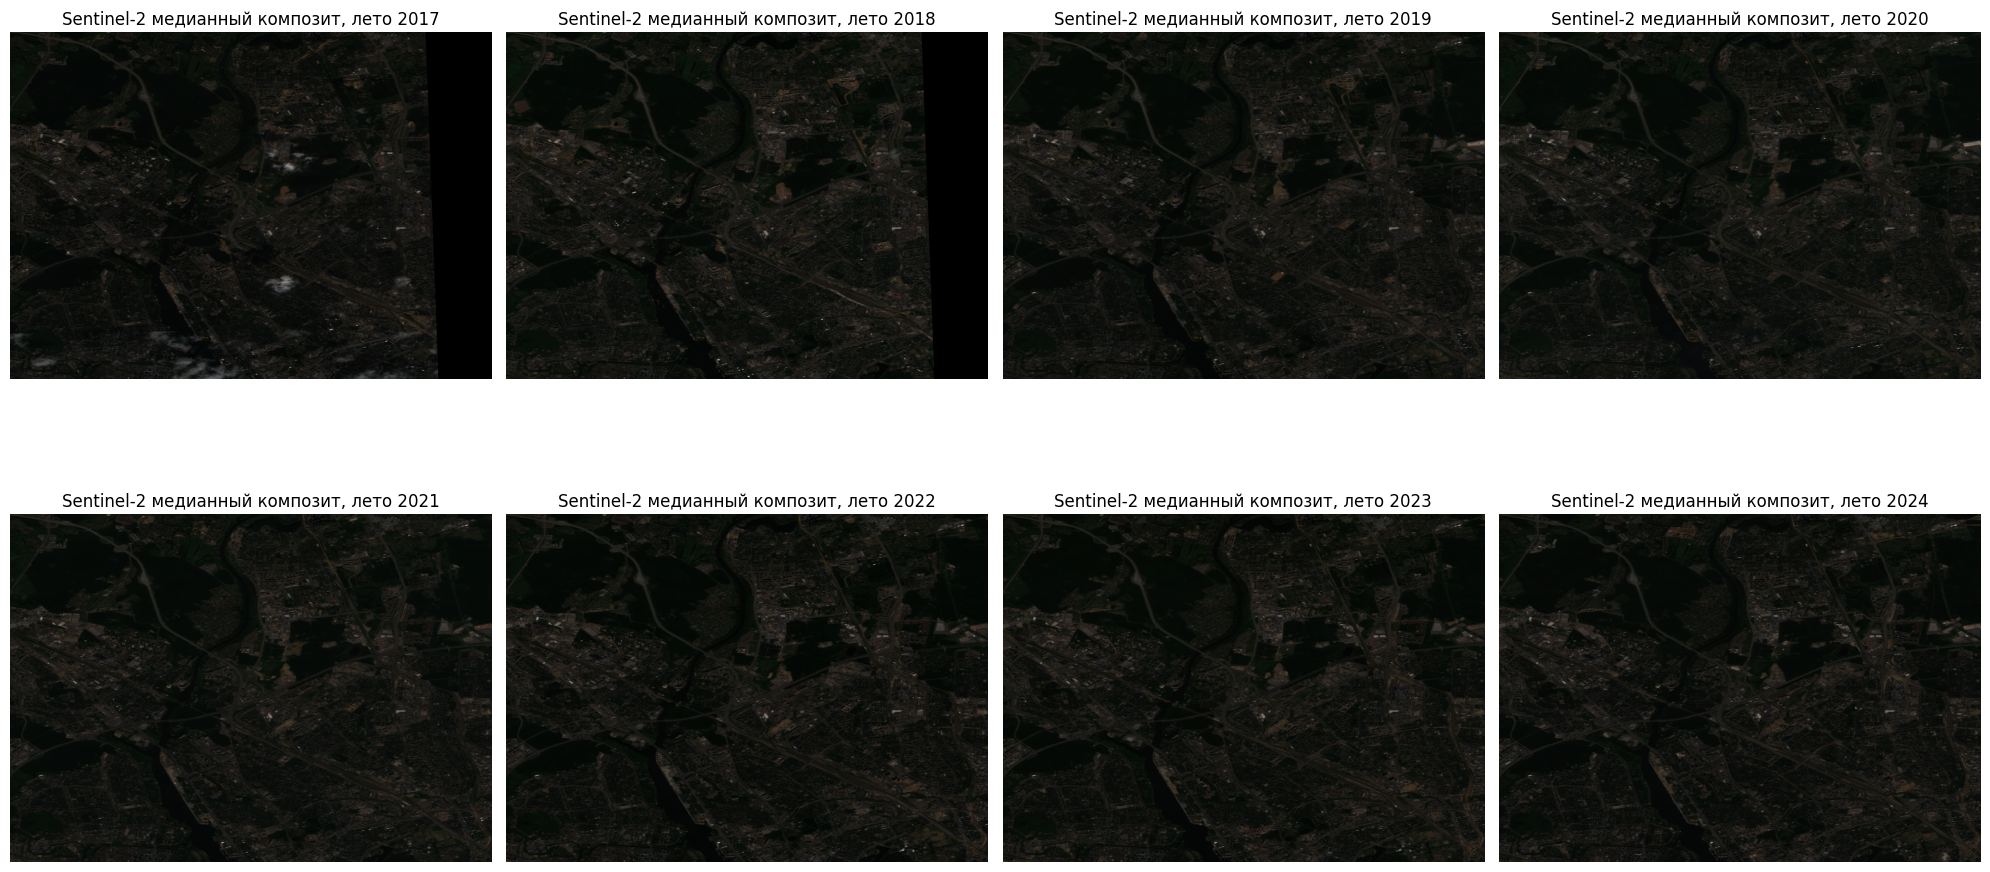

In [12]:
# 4.1. Загрузка и проверка растров Sentinel-2, вывод в видимом диапазоне (RGB)
# Теория: Т5, яч. 14 (#scrollTo=7) - rasterio.open, meta
#         Т5, яч. 81 (#scrollTo=57) - np.dstack((nir_band, red_band, green_band)).clip(0, 1)
sentinel_paths = {year: os.path.join('sentinel2', f'sentinel2_summer_{year}.tif')
                  for year in years}

# Название каналов в порядке их экспорта (bands = ['B2','B3','B4','B8','B11'])
band_names = ["B2 (Blue)", "B3 (Green)", "B4 (Red)", "B8 (NIR)", "B11 (SWIR)"]

# Проверка метаданных растра
src = rasterio.open(sentinel_paths[2024])
print(src)
print("\nmeta:", src.meta)
print("\nCRS:", src.crs, "| размеры (w, h):", (src.width, src.height))
print("Разрешение (x, y):", src.res, "| границы:", src.bounds)
print("Каналы:", band_names)

# Вывод всех растров в видимом диапазоне (R=B4, G=B3, B=B2)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 11))

for ax, year in zip(axes.flatten(), years):
    with rasterio.open(sentinel_paths[year]) as src:
        red_band = src.read(3)
        green_band = src.read(2)
        blue_band = src.read(1)
        extent = rasterio.plot.plotting_extent(src)

    rgb = np.dstack((red_band, green_band, blue_band)).clip(0, 1)

    ax.imshow(rgb, extent=extent)
    ax.set_title(f'Sentinel-2 медианный композит, лето {year}')
    ax.set_axis_off()

plt.tight_layout()
plt.show()

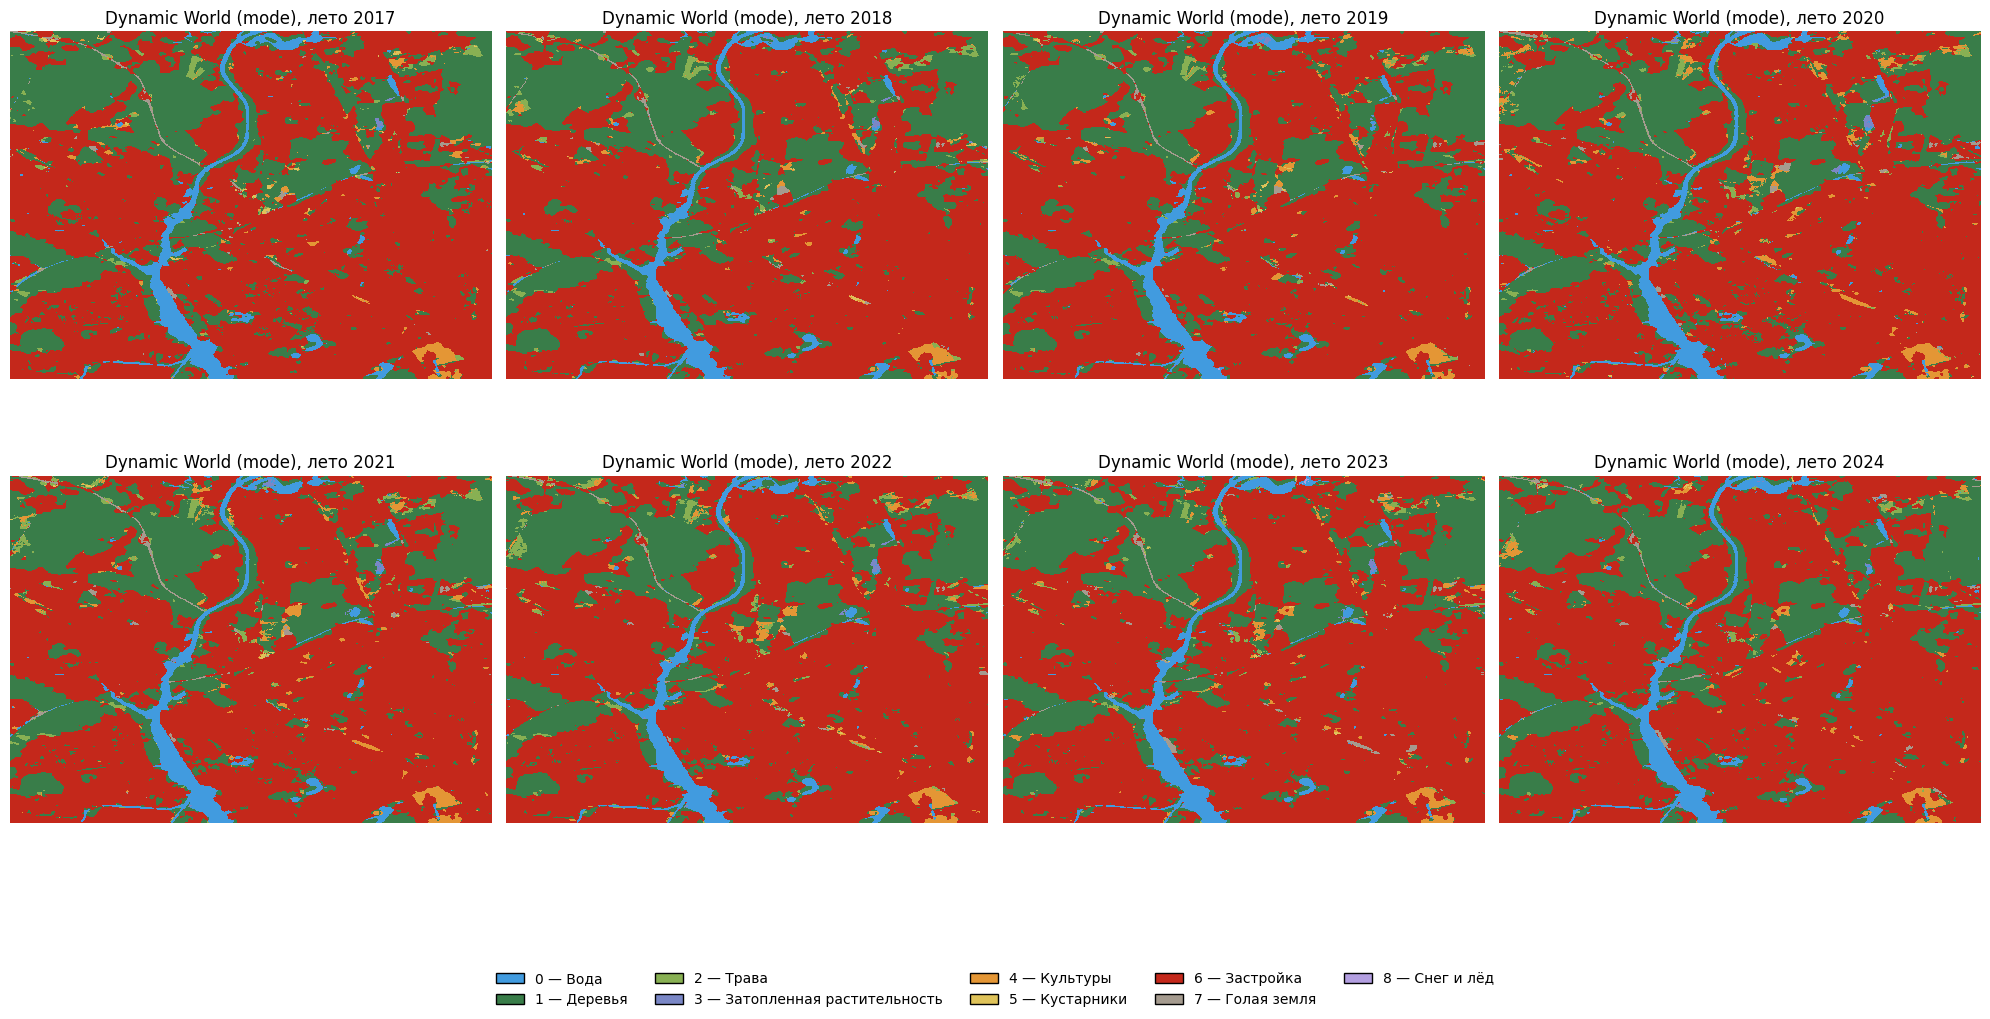

In [13]:
# 4.1. Вывод всех карт классификаций Dynamic World
# Палитра - из landcover_vis (яч. 23 задания), легенда - по образцу Т4, яч. 14/15
landcover_paths = {year: os.path.join('DYNAMICWORLD', f'DYNAMICWORLD_summer_{year}.tif')
                   for year in years}

landcover_names = {
    0: 'Вода', 1: 'Деревья', 2: 'Трава', 3: 'Затопленная растительность',
    4: 'Культуры', 5: 'Кустарники', 6: 'Застройка', 7: 'Голая земля',
    8: 'Снег и лёд'
}
palette_dw = ['#419bdf', '#397d49', '#88b053', '#7a87c6', '#e49635',
              '#dfc35a', '#c4281b', '#a59b8f', '#b39fe1']
cmap_landcover = ListedColormap(palette_dw)

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 11))

for ax, year in zip(axes.flatten(), years):
    with rasterio.open(landcover_paths[year]) as src:
        data = src.read(1)
        extent = rasterio.plot.plotting_extent(src)

    ax.imshow(np.ma.masked_invalid(data.astype('float32')),
              cmap=cmap_landcover, vmin=0, vmax=len(palette_dw) - 1,
              extent=extent, interpolation='nearest')
    ax.set_title(f'Dynamic World (mode), лето {year}')
    ax.set_axis_off()

handles = [Patch(facecolor=color, edgecolor='black',
                 label=f'{code} — {name}')
           for code, (name, color) in enumerate(zip(landcover_names.values(),
                                                    palette_dw))]
fig.legend(handles=handles, loc='lower center', ncol=5, fontsize=10, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

### **4.2. Рассчитать все 8 индексов для каждого года (2015-2024)**


> **Примечание.** В качестве примера рассчета индексов можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/4qBeIg





**Спектральные индексы** — это математические комбинации значений отражения в разных спектральных каналах, позволяющие выделить определенные типы объектов.








#### **Таблица 1. Основные спектральные индексы для анализа земного покрова**




| **Индекс** | **Формула** | **Назначение** | **Каналы Sentinel-2** |
|------------|-------------|----------------|------------------------|
| **NDVI** (Normalized Difference Vegetation Index) | (NIR - RED) / (NIR + RED) | Оценка состояния растительности | (B8 - B4) / (B8 + B4) |
| **NDWI** (Normalized Difference Water Index) | (GREEN - NIR) / (GREEN + NIR) | Выделение водных объектов | (B3 - B8) / (B3 + B8) |
| **NDBI** (Normalized Difference Built-up Index) | (SWIR - NIR) / (SWIR + NIR) | Выделение застроенных территорий | (B11 - B8) / (B11 + B8) |
| **SAVI** (Soil Adjusted Vegetation Index) | ((NIR - RED) / (NIR + RED + L)) * (1 + L), L=0.5 | Растительность с учетом почвы | ((B8 - B4) / (B8 + B4 + 0.5)) * 1.5 |
| **EVI** (Enhanced Vegetation Index) | 2.5 * ((NIR - RED) / (NIR + 6*RED - 7.5*BLUE + 1)) | Улучшенный вегетационный индекс | 2.5 * ((B8 - B4) / (B8 + 6*B4 - 7.5*B2 + 1)) |
| **MNDWI** (Modified NDWI) | (GREEN - SWIR) / (GREEN + SWIR) | Модифицированный водный индекс | (B3 - B11) / (B3 + B11) |
| **BSI** (Bare Soil Index) | ((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE)) | Открытая почва | ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2)) |
| **NDSI** (Normalized Difference Snow Index) | (GREEN - SWIR) / (GREEN + SWIR) | Снежный покров | (B3 - B11) / (B3 + B11) |


#### **Таблица 2. Интерпретация значений NDVI**



| **Диапазон NDVI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| < 0.0 | Вода | Водные поверхности, снег |
| 0.0 - 0.1 | Открытая почва | Песок, камни, бетон |
| 0.1 - 0.2 | Разреженная растительность | Степи, пустыни |
| 0.2 - 0.4 | Умеренная растительность | Кустарники, луга |
| 0.4 - 0.6 | Плотная растительность | Лиственные леса |
| > 0.6 | Очень плотная растительность | Тропические леса, хвойные леса |

#### **Таблица 3. Интерпретация значений NDWI**



| **Диапазон NDWI** | **Тип объекта** | **Описание** |
|-------------------|-----------------|--------------|
| > 0.3 | Водные объекты | Реки, озера, пруды |
| 0.0 - 0.3 | Влажная почва/растительность | Болота, заливные луга |
| -0.3 - 0.0 | Сухая растительность | Обычная растительность |
| < -0.3 | Застройка/почва | Городская застройка, открытая почва |

#### **Таблица 4. Интерпретация значений NDBI**



| **Диапазон NDBI** | **Тип территории** | **Характеристика** |
|-------------------|-------------------|---------------------|
| > 0.0 | Застроенные территории | Города, промзоны |
| -0.1 - 0.0 | Смешанные территории | Пригороды, села |
| < -0.1 | Природные территории | Леса, поля, водоемы |

#### **Таблица 5. Интерпретация значений SAVI**



| **Диапазон SAVI** | **Тип покрова** | **Описание** |
|-------------------|-----------------|---------------|
| < 0.1 | Открытая почва/вода | Водные объекты, голая почва |
| 0.1 - 0.2 | Очень разреженная растительность | Пустыни, каменистые участки |
| 0.2 - 0.4 | Разреженная растительность | Степи, саванны |
| 0.4 - 0.6 | Умеренная растительность | Сельхозугодья, луга |
| > 0.6 | Плотная растительность | Леса, густые кустарники |

#### **Таблица 6. Интерпретация значений EVI**



| **Диапазон EVI** | **Состояние растительности** | **Характеристика** |
|------------------|------------------------------|---------------------|
| < 0.0 | Нет растительности | Вода, снег, облака |
| 0.0 - 0.2 | Минимальная растительность | Голая почва, урбанизированные территории |
| 0.2 - 0.3 | Низкая биомасса | Травянистая растительность |
| 0.3 - 0.5 | Средняя биомасса | Кустарники, молодые посевы |
| 0.5 - 0.8 | Высокая биомасса | Зрелые леса, интенсивное сельское хозяйство |
| > 0.8 | Очень высокая биомасса | Тропические леса |

#### **Таблица 7. Интерпретация значений MNDWI**



| **Диапазон MNDWI** | **Тип объекта** | **Характеристика** |
|--------------------|-----------------|---------------------|
| > 0.5 | Глубокая вода | Озера, моря, водохранилища |
| 0.2 - 0.5 | Мелкая вода | Реки, каналы, мелководья |
| 0.0 - 0.2 | Влажные территории | Болота, рисовые поля |
| < 0.0 | Суша | Растительность, почва, застройка |

#### **Таблица 8. Интерпретация значений BSI**



| **Диапазон BSI** | **Тип поверхности** | **Описание** |
|-------------------|-------------------|---------------|
| > 0.1 | Открытая почва | Пашни, карьеры, пустыни |
| 0.0 - 0.1 | Частично покрытая почва | Разреженная растительность |
| -0.1 - 0.0 | Смешанный покров | Переходные зоны |
| < -0.1 | Растительность/вода | Леса, водоемы, плотная растительность |

#### **Таблица 9. Интерпретация значений NDSI**



| **Диапазон NDSI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| > 0.4 | Снежный покров | Чистый снег, ледники |
| 0.2 - 0.4 | Частичный снежный покров | Смешанный снег с растительностью |
| 0.0 - 0.2 | Возможный снег/лед | Тающий снег, иней, облака |
| -0.2 - 0.0 | Переходная зона | Влажная почва, туман |
| < -0.2 | Бесснежные территории | Растительность, почва, вода |

In [14]:
# 4.2. Расчёт всех 8 спектральных индексов для каждого года
# Теория: Т5, Раздел №4, яч. 84 (#scrollTo=59) - расчёт индексов средствами numpy
#         Т2, Раздел 3.3, яч. 55 (#scrollTo=328bbf8f) - формулы NDVI, NDWI, NDBI, EVI
#         Таблица 1 проектной работы - формулы SAVI, MNDWI, BSI, NDSI
L = 0.5   # коэффициент регулирования почвы для SAVI (Таблица 1)


def read_band(src, band):
    """Читает канал как float32 и приводит no-data значения к NaN."""
    data = src.read(band).astype('float32')
    if src.nodata is not None and not np.isnan(src.nodata):
        data[data == src.nodata] = np.nan
    return data


indices = {year: {} for year in years}
profiles = {}

for year in years:
    with rasterio.open(sentinel_paths[year]) as src:
        # Профиль растра понадобится при сохранении индексов (яч. 58)
        profiles[year] = src.profile.copy()

        blue_band = read_band(src, 1)    # B2 - синий
        green_band = read_band(src, 2)   # B3 - зелёный
        red_band = read_band(src, 3)     # B4 - красный
        nir_band = read_band(src, 4)     # B8 - ближний ИК
        swir_band = read_band(src, 5)    # B11 - коротковолновый ИК

    with np.errstate(divide='ignore', invalid='ignore'):
        # NDVI = (NIR - RED) / (NIR + RED)
        ndvi = ((nir_band - red_band) / (nir_band + red_band)).clip(-1, 1)

        # NDWI = (GREEN - NIR) / (GREEN + NIR)
        ndwi = ((green_band - nir_band) / (green_band + nir_band)).clip(-1, 1)

        # NDBI = (SWIR - NIR) / (SWIR + NIR)
        ndbi = ((swir_band - nir_band) / (swir_band + nir_band)).clip(-1, 1)

        # SAVI = ((NIR - RED) / (NIR + RED + L)) * (1 + L), L = 0.5
        savi = (((nir_band - red_band) / (nir_band + red_band + L))
                * (1 + L)).clip(-1, 1)

        # EVI = 2.5 * ((NIR - RED) / (NIR + 6*RED - 7.5*BLUE + 1))
        evi = (2.5 * ((nir_band - red_band)
                      / (nir_band + 6 * red_band - 7.5 * blue_band + 1))).clip(-1, 1)

        # MNDWI = (GREEN - SWIR) / (GREEN + SWIR)
        mndwi = ((green_band - swir_band) / (green_band + swir_band)).clip(-1, 1)

        # BSI = ((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE))
        bsi = ((((swir_band + red_band) - (nir_band + blue_band))
                / ((swir_band + red_band) + (nir_band + blue_band)))).clip(-1, 1)

        # NDSI = (GREEN - SWIR) / (GREEN + SWIR) - по Таблице 1 совпадает с MNDWI
        ndsi = mndwi.copy()

    indices[year] = {
        'NDVI': ndvi, 'NDWI': ndwi, 'NDBI': ndbi, 'SAVI': savi,
        'EVI': evi, 'MNDWI': mndwi, 'BSI': bsi, 'NDSI': ndsi
    }

    print(f"{year}: индексов - {len(indices[year])}, "
          f"средний NDVI = {np.nanmean(ndvi):.3f}, "
          f"min = {np.nanmin(ndvi):.3f}, max = {np.nanmax(ndvi):.3f}")

2017: индексов - 8, средний NDVI = 0.500, min = -0.365, max = 1.000
2018: индексов - 8, средний NDVI = 0.523, min = -0.517, max = 1.000
2019: индексов - 8, средний NDVI = 0.511, min = -0.261, max = 0.918
2020: индексов - 8, средний NDVI = 0.512, min = -0.287, max = 0.914
2021: индексов - 8, средний NDVI = 0.518, min = -0.246, max = 0.922
2022: индексов - 8, средний NDVI = 0.536, min = -0.604, max = 0.937
2023: индексов - 8, средний NDVI = 0.521, min = -0.383, max = 0.933
2024: индексов - 8, средний NDVI = 0.511, min = -0.277, max = 0.913


### **4.3. Визуализировать каждый индекс для 2024 года с соответствующей цветовой шкалой**



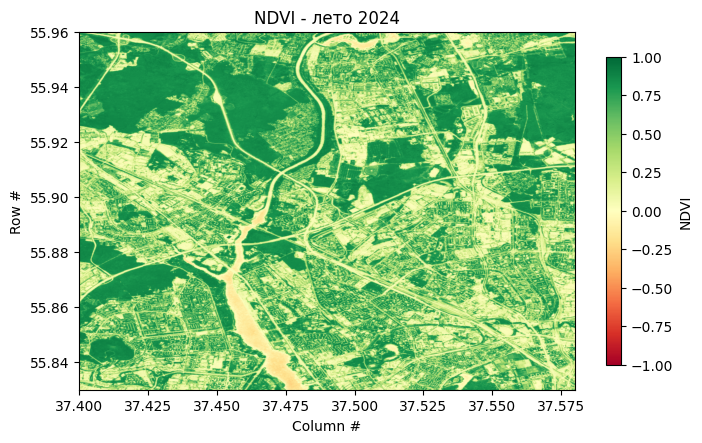

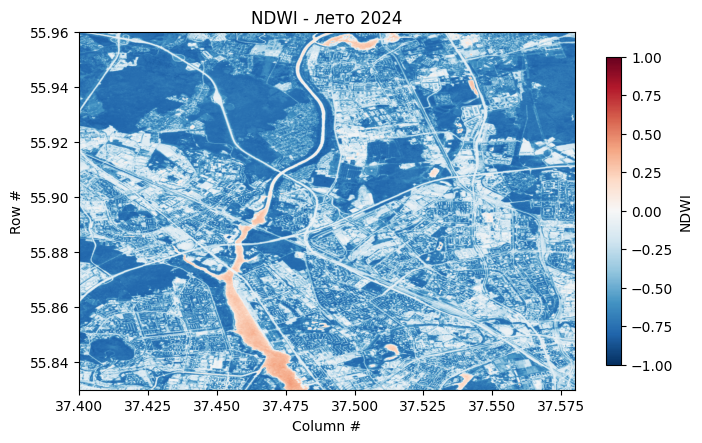

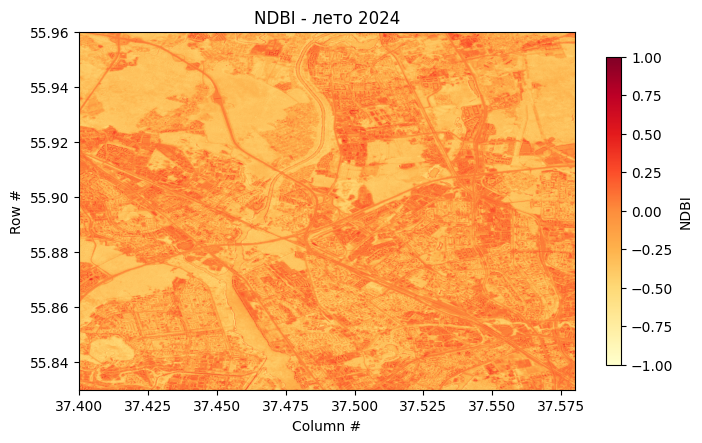

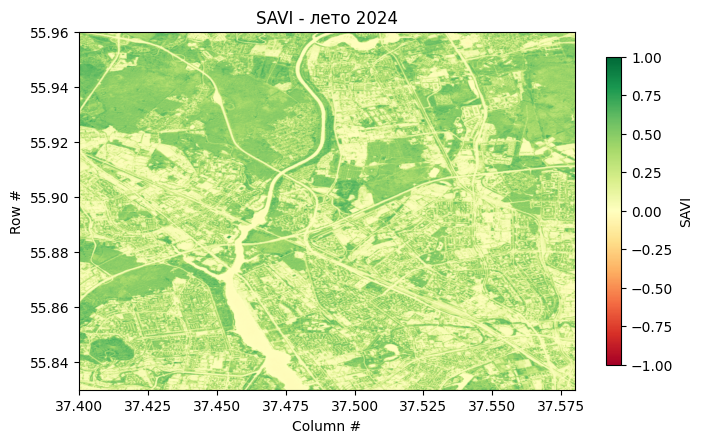

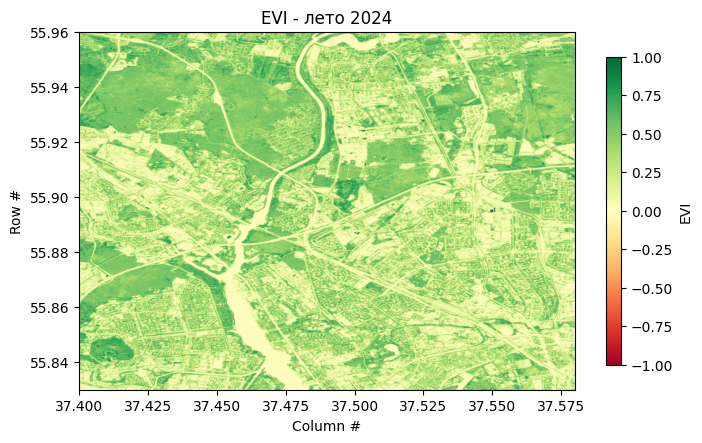

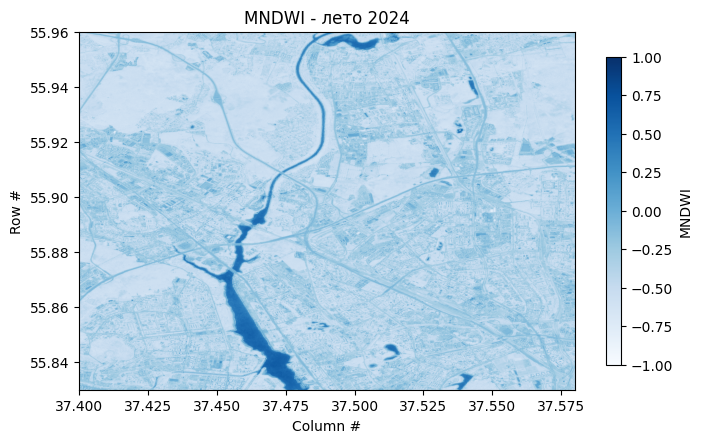

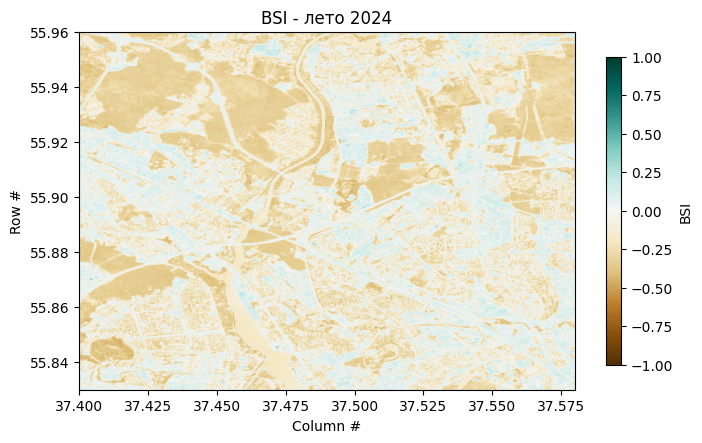

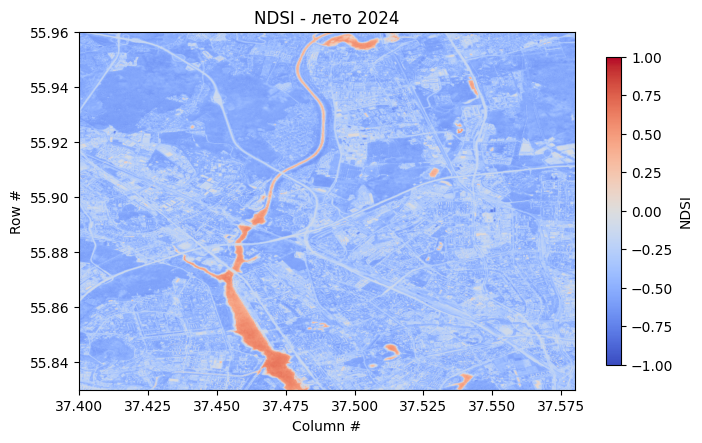

In [15]:
# 4.3. Визуализация каждого индекса за 2024 год с цветовой шкалой
# Теория: Т5, Раздел №4, яч. 84 (#scrollTo=59); подписи осей и colorbar - оттуда же
# Диапазоны и интерпретация - Таблицы 2-9 проектной работы
vis_params_indices = {
    'NDVI':  {'cmap': 'RdYlGn', 'min': -1, 'max': 1},   # Таблица 2
    'NDWI':  {'cmap': 'RdBu_r', 'min': -1, 'max': 1},   # Таблица 3
    'NDBI':  {'cmap': 'YlOrRd', 'min': -1, 'max': 1},   # Таблица 4
    'SAVI':  {'cmap': 'RdYlGn', 'min': -1, 'max': 1},   # Таблица 5
    'EVI':   {'cmap': 'RdYlGn', 'min': -1, 'max': 1},   # Таблица 6
    'MNDWI': {'cmap': 'Blues',  'min': -1, 'max': 1},   # Таблица 7
    'BSI':   {'cmap': 'BrBG',   'min': -1, 'max': 1},   # Таблица 8
    'NDSI':  {'cmap': 'coolwarm', 'min': -1, 'max': 1}  # Таблица 9
}

with rasterio.open(sentinel_paths[2024]) as src:
    extent = rasterio.plot.plotting_extent(src)

for index_name, params in vis_params_indices.items():
    data = indices[2024][index_name]

    plt.figure(figsize=(8, 8))
    plt.imshow(data, cmap=params['cmap'], vmin=params['min'],
               vmax=params['max'], extent=extent)
    plt.colorbar(label=index_name, shrink=0.5)
    plt.title(f"{index_name} - лето 2024")
    plt.xlabel("Column #")
    plt.ylabel("Row #")
    plt.show()

### **4.4. Сохранить все рассчитанные индексы в отдельные GeoTIFF файлы с сохранением геопривязки (сохранить в соответствующие папки по годам)**



In [16]:
# 4.4. Сохранение всех индексов в GeoTIFF с сохранением геопривязки
# Теория: Т5, Раздел №5, яч. 88 (#scrollTo=61), 90 (#scrollTo=63), 92 (#scrollTo=65)
for year in years:
    output_dir = os.path.join('indices', str(year))
    os.makedirs(output_dir, exist_ok=True)

    # Обновляем профиль: один канал, float32, сжатие LZW
    profile = profiles[year].copy()
    profile.update(dtype=rasterio.float32, count=1, compress="lzw")

    for index_name, data in indices[year].items():
        output_raster_path = os.path.join(output_dir, f'{index_name}_{year}.tif')

        # Открываем файл для записи с использованием параметров профиля
        with rasterio.open(output_raster_path, "w", **profile) as dst:
            dst.write(data.astype('float32'), 1)

        print(f"Растровые данные были записаны в файл: {output_raster_path}")

Растровые данные были записаны в файл: indices/2017/NDVI_2017.tif
Растровые данные были записаны в файл: indices/2017/NDWI_2017.tif
Растровые данные были записаны в файл: indices/2017/NDBI_2017.tif
Растровые данные были записаны в файл: indices/2017/SAVI_2017.tif
Растровые данные были записаны в файл: indices/2017/EVI_2017.tif
Растровые данные были записаны в файл: indices/2017/MNDWI_2017.tif
Растровые данные были записаны в файл: indices/2017/BSI_2017.tif
Растровые данные были записаны в файл: indices/2017/NDSI_2017.tif
Растровые данные были записаны в файл: indices/2018/NDVI_2018.tif
Растровые данные были записаны в файл: indices/2018/NDWI_2018.tif
Растровые данные были записаны в файл: indices/2018/NDBI_2018.tif
Растровые данные были записаны в файл: indices/2018/SAVI_2018.tif
Растровые данные были записаны в файл: indices/2018/EVI_2018.tif
Растровые данные были записаны в файл: indices/2018/MNDWI_2018.tif
Растровые данные были записаны в файл: indices/2018/BSI_2018.tif
Растровые да

## **5. Сегментация и классификация**

**Сегментация** — процесс разделения изображения на однородные регионы (сегменты) на основе заданных критериев .


### **5.1. Многопороговая сегментация с использованием спектральных индексов**



**Задание:** Реализовать классификацию земного покрова путем замены значений пикселей в растрах индексов на метки классов согласно пороговым правилам.

**Пояснение:** По сути необходимо преобразовать непрерывные значения индексов в дискретные классы (метки) на основе пороговых значений из Таблиц 2-9. Каждому пикселю присваивается числовая метка класса (0-8) в зависимости от значений спектральных индексов.






**Алгоритм многопороговой сегментации:**
1. Создать пустой растр для меток классов (заполнить значением -1 или 255 для "неклассифицировано")
2. Последовательно применить правила классификации
3. Каждое правило проверяется только для еще не классифицированных пикселей
4. Присвоить соответствующую метку класса пикселям, удовлетворяющим условию

**Иерархия правил классификации (применять строго последовательно):**
1. **Вода (метка=0)**: (NDWI > 0.3) ИЛИ (MNDWI > 0.2)
2. **Снег/лед (метка=1)**: (NDSI > 0.4) И (еще не классифицировано)
3. **Застройка (метка=2)**: (NDBI > 0.0) И (NDVI < 0.2) И (еще не классифицировано)
4. **Густая растительность (метка=3)**: ((NDVI > 0.6) ИЛИ (EVI > 0.5)) И (еще не классифицировано)
5. **Умеренная растительность (метка=4)**: (0.3 ≤ NDVI ≤ 0.6) И (еще не классифицировано)
6. **Разреженная растительность (метка=5)**: (0.1 ≤ NDVI < 0.3) И (еще не классифицировано)
7. **Открытая почва (метка=6)**: (BSI > 0.0) И (NDVI < 0.1) И (еще не классифицировано)
8. **Прочее (метка=7)**: все оставшиеся неклассифицированные пиксели


**(МОЖЕТЕ СФОРМУЛИРОВАТЬ СВОИ ПРАВИЛА, ОСНОВЫВАЯСЬ НА ТАБЛИЦАХ, ПРИВЕДЕННЫХ ВЫШЕ!)**

In [17]:
# 5.1. Многопороговая сегментация с использованием спектральных индексов
# Алгоритм и иерархия правил - яч. 63-64 задания, пороги - Таблицы 2-9
# Реализация средствами numpy (растровая алгебра) - Т5, яч. 84 (#scrollTo=59)
class_names = {
    0: 'Вода',
    1: 'Снег/лёд',
    2: 'Застройка',
    3: 'Густая растительность',
    4: 'Умеренная растительность',
    5: 'Разреженная растительность',
    6: 'Открытая почва',
    7: 'Прочее'
}
class_colors = ['#419bdf', '#ffffff', '#c4281b', '#397d49',
                '#88b053', '#7a87c6', '#a59b8f', '#808080']
NODATA = 255   # значение "нет данных" (облако на всех снимках периода)


def multisource_segmentation(idx):
    """
    Многопороговая сегментация по спектральным индексам.

    Параметры:
        idx (dict): словарь индексов года {'NDVI': ..., 'NDWI': ..., ...}

    Возвращает:
        np.ndarray (int16): растр меток классов 0-7, NODATA - нет данных
    """
    ndvi = idx['NDVI']
    nodata_mask = np.isnan(ndvi)

    # Пропускаем нули в масках для пикселей без данных
    ndvi = np.nan_to_num(ndvi)
    ndwi = np.nan_to_num(idx['NDWI'])
    ndbi = np.nan_to_num(idx['NDBI'])
    ndsi = np.nan_to_num(idx['NDSI'])
    mndwi = np.nan_to_num(idx['MNDWI'])
    bsi = np.nan_to_num(idx['BSI'])
    evi = np.nan_to_num(idx['EVI'])

    # Шаг 1 алгоритма: пустой растр меток (-1 - неклассифицировано)
    labels = np.full(ndvi.shape, -1, dtype=np.int16)

    # Шаг 2-3: правила применяются последовательно, каждое - только
    # для ещё неклассифицированных пикселей (условие labels == -1)
    labels[(ndwi > 0.3) | (mndwi > 0.2)] = 0                                   # 1. Вода
    labels[(ndsi > 0.4) & (labels == -1)] = 1                                   # 2. Снег/лёд
    labels[(ndbi > 0.0) & (ndvi < 0.2) & (labels == -1)] = 2                    # 3. Застройка
    labels[((ndvi > 0.6) | (evi > 0.5)) & (labels == -1)] = 3                   # 4. Густая раст-ть
    labels[(ndvi >= 0.3) & (ndvi <= 0.6) & (labels == -1)] = 4                  # 5. Умеренная раст-ть
    labels[(ndvi >= 0.1) & (ndvi < 0.3) & (labels == -1)] = 5                   # 6. Разреженная раст-ть
    labels[(bsi > 0.0) & (ndvi < 0.1) & (labels == -1)] = 6                     # 7. Открытая почва
    labels[labels == -1] = 7                                                    # 8. Прочее

    labels[nodata_mask] = NODATA
    return labels


# Сегментация медианного композита 2024 года
segmented_labels = multisource_segmentation(indices[2024])
print(f"Размер растра меток: {segmented_labels.shape}")
print(f"Уникальные метки: {np.unique(segmented_labels)}")

Размер растра меток: (1448, 2005)
Уникальные метки: [0 2 3 4 5 6 7]



### **5.2. Подсчет количества пикселей каждого класса**



**Задание:** После замены значений индексов на метки классов, подсчитать количество пикселей для каждой метки класса.

**Пояснение:** Используйте функции numpy.unique() или аналогичные для подсчета количества пикселей с каждой меткой. Это позволит получить статистику распределения классов на изображении.

**Что нужно получить:**
- Массив уникальных меток классов (0-7)
- Количество пикселей для каждой метки
- Процентное соотношение классов от общего числа пикселей

In [18]:
# 5.2. Подсчет количества пикселей каждого класса (numpy.unique)
def count_pixels(labels, names, nodata_name='Нет данных'):
    """
    Считает количество пикселей каждой метки класса и их процентное соотношение.

    Возвращает:
        pd.DataFrame: Метка, Класс, Пикселей, Доля, %
    """
    unique_labels, counts = np.unique(labels, return_counts=True)
    valid_total = int(counts[unique_labels != NODATA].sum())

    rows = []
    for label, count in zip(unique_labels, counts):
        if label == NODATA:
            name, percent = nodata_name, np.nan
        else:
            name = names[int(label)]
            percent = round(100 * int(count) / valid_total, 2)
        rows.append({'Метка': int(label), 'Класс': name,
                     'Пикселей': int(count), 'Доля, %': percent})

    return pd.DataFrame(rows)


counts_2024 = count_pixels(segmented_labels, class_names)
print("Общее число пикселей ROI:", segmented_labels.size)
display(counts_2024)

Общее число пикселей ROI: 2903240


,Метка,Класс,Пикселей,"Доля, %"
0,0,Вода,64277,2.21
1,2,Застройка,467313,16.10
2,3,Густая растительность,1395557,48.07
3,4,Умеренная растительность,632464,21.78
4,5,Разреженная растительность,289312,9.97
5,6,Открытая почва,35312,1.22
6,7,Прочее,19005,0.65


### **5.3. Применение сегментации ко всем временным срезам**




**Задание:** Применить разработанный алгоритм сегментации ко всем медианным композитам (2017-2024).

**Пояснение:** Использовать одинаковые пороговые значения для всех лет для обеспечения сопоставимости результатов при анализе динамики. Сохранить результаты сегментации как растры с метками классов.

**Выходные данные:**
- 8 растров с метками классов (по одному на каждый год)
- Таблица с количеством пикселей каждого класса для каждого года
- Формат сохранения: GeoTIFF с сохранением геопривязки

In [19]:
# 5.3. Применение сегментации ко всем годам + сохранение GeoTIFF
# Сохранение: Т5, Раздел №5, яч. 88/90/92
segmented = {}
pixel_counts = pd.DataFrame(index=list(class_names.values()),
                           columns=years, dtype=int)

for year in years:
    # Одни и те же пороговые значения для всех лет - сопоставимость результатов
    labels = multisource_segmentation(indices[year])
    segmented[year] = labels

    output_dir = os.path.join('segmentation', str(year))
    os.makedirs(output_dir, exist_ok=True)

    profile = profiles[year].copy()
    profile.update(dtype=rasterio.int16, count=1, compress="lzw", nodata=NODATA)

    output_raster_path = os.path.join(output_dir, f'segmentation_summer_{year}.tif')
    with rasterio.open(output_raster_path, "w", **profile) as dst:
        dst.write(labels, 1)
    print(f"Растровые данные были записаны в файл: {output_raster_path}")

    counts_year = count_pixels(labels, class_names).set_index('Класс')
    pixel_counts[year] = counts_year['Пикселей'].reindex(pixel_counts.index).fillna(0).astype(int)

print("\nТаблица количества пикселей каждого класса по годам:")
display(pixel_counts)

Растровые данные были записаны в файл: segmentation/2017/segmentation_summer_2017.tif
Растровые данные были записаны в файл: segmentation/2018/segmentation_summer_2018.tif
Растровые данные были записаны в файл: segmentation/2019/segmentation_summer_2019.tif
Растровые данные были записаны в файл: segmentation/2020/segmentation_summer_2020.tif
Растровые данные были записаны в файл: segmentation/2021/segmentation_summer_2021.tif
Растровые данные были записаны в файл: segmentation/2022/segmentation_summer_2022.tif
Растровые данные были записаны в файл: segmentation/2023/segmentation_summer_2023.tif
Растровые данные были записаны в файл: segmentation/2024/segmentation_summer_2024.tif

Таблица количества пикселей каждого класса по годам:


,2017,2018,2019,2020,2021,2022,2023,2024
Вода,52005,60924,58195,52589,60103,51219,60662,64277
Снег/лёд,0,0,0,0,0,0,0,0
Застройка,414779,382262,455145,465651,469383,447386,449064,467313
Густая растительность,1165427,1227806,1358770,1374986,1395219,1442822,1396906,1395557
Умеренная растительность,585619,549603,687796,679549,659206,628005,646904,632464
Разреженная растительность,279966,272971,299837,286890,279843,283538,298679,289312
Открытая почва,22343,30428,27670,26273,25905,31624,32807,35312
Прочее,21401,17546,15827,17302,13581,18646,18218,19005


### **5.4. Визуализация результатов сегментации**






**Задание:** Создать тематические карты классификации с легендой.

**Пояснение:** Назначить каждой метке класса соответствующий цвет для визуализации. Использовать стандартную цветовую схему для классов земного покрова.

**Цветовая схема для визуализации:**
- 0 - Вода: синий (#419bdf)
- 1 - Снег/лед: белый (#ffffff)  
- 2 - Застройка: красный (#c4281b)
- 3 - Густая растительность: темно-зеленый (#397d49)
- 4 - Умеренная растительность: зеленый (#88b053)
- 5 - Разреженная растительность: светло-зеленый (#7a87c6)
- 6 - Открытая почва: коричневый (#a59b8f)
- 7 - Прочее: серый (#808080)

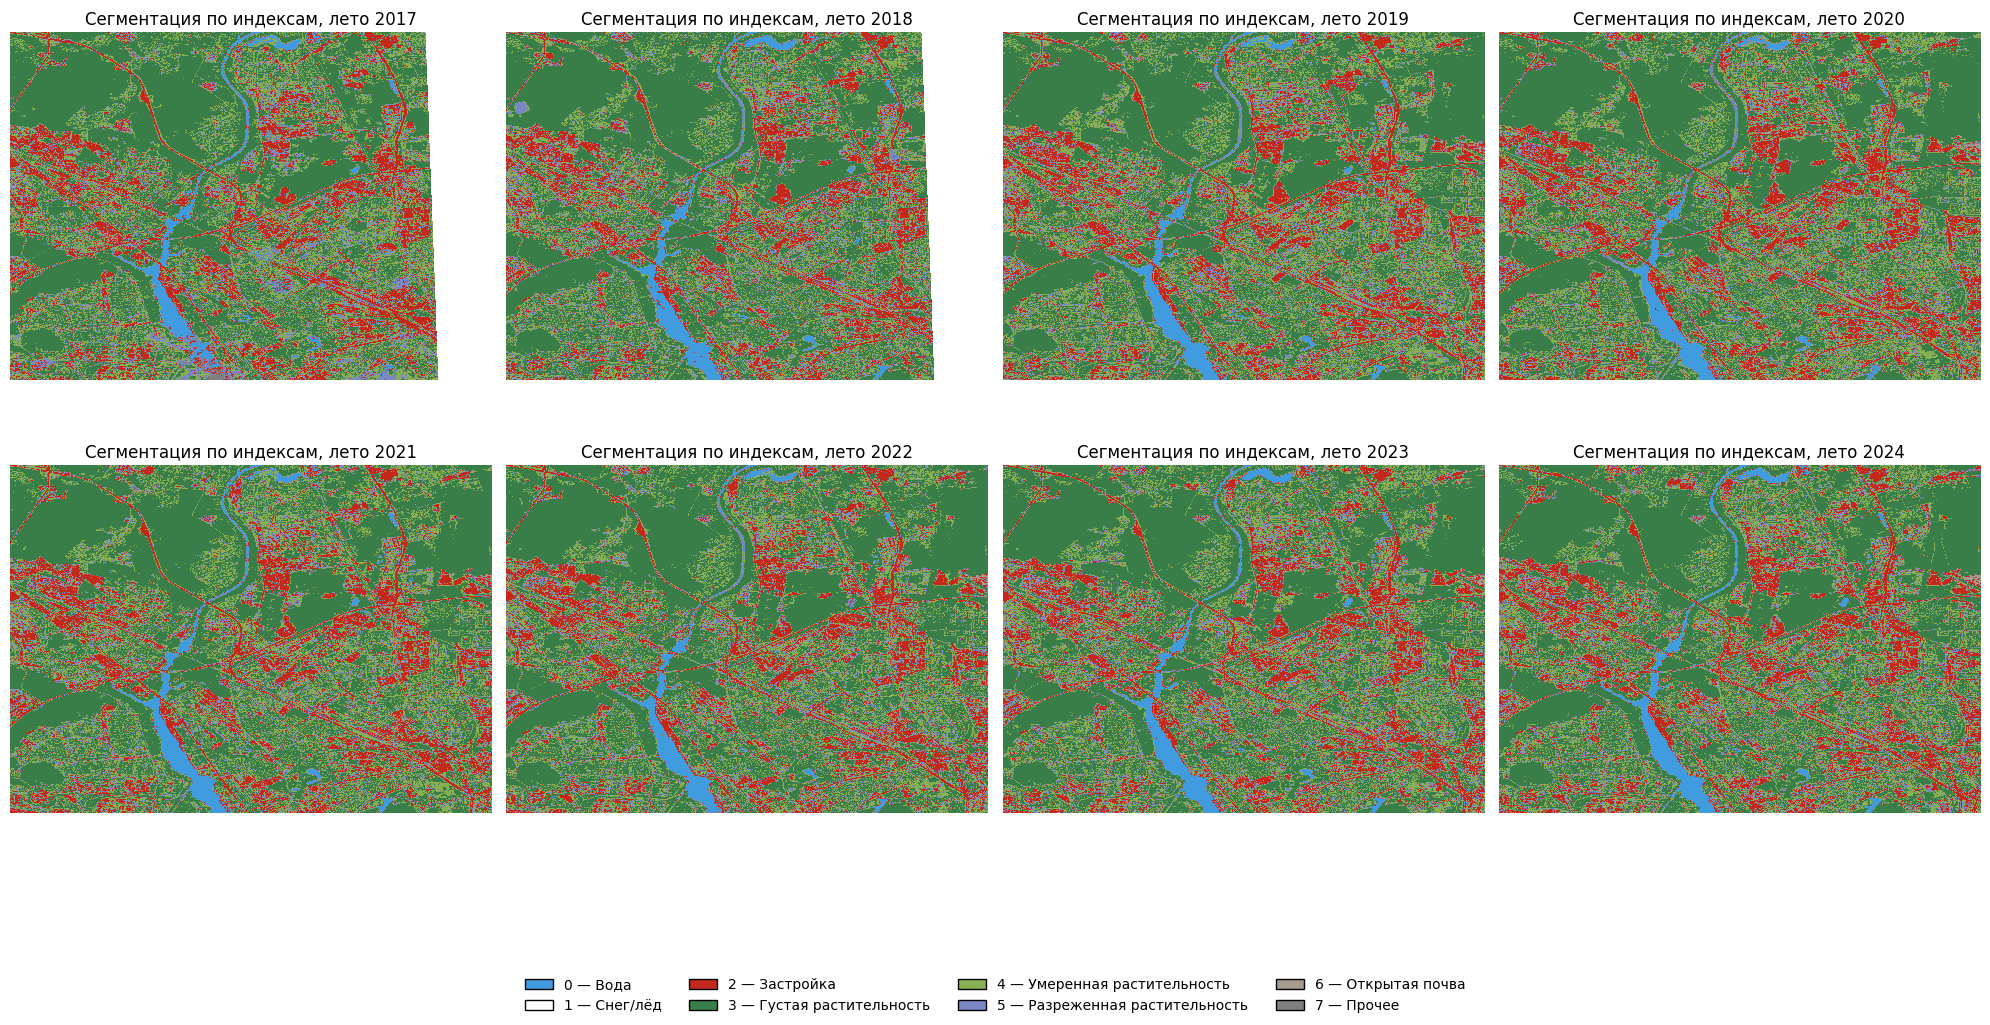

In [20]:
# 5.4. Тематические карты классификации с легендой
# Цветовая схема - яч. 74 задания; легенда по аналогии с Т4, яч. 14/15
cmap_segmentation = ListedColormap(class_colors)

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 11))

for ax, year in zip(axes.flatten(), years):
    with rasterio.open(sentinel_paths[year]) as src:
        extent = rasterio.plot.plotting_extent(src)

    data = np.ma.masked_equal(segmented[year], NODATA)
    ax.imshow(data, cmap=cmap_segmentation, vmin=0, vmax=len(class_colors) - 1,
              extent=extent, interpolation='nearest')
    ax.set_title(f'Сегментация по индексам, лето {year}')
    ax.set_axis_off()

handles = [Patch(facecolor=color, edgecolor='black',
                 label=f'{code} — {name}')
           for code, (name, color) in enumerate(zip(class_names.values(),
                                                    class_colors))]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=10, frameon=False)
plt.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()

## **6. Анализ динамики изменений на сегментированных растрах**

### **6.1. Рассчитать площади всех классов для каждого года**



**Формула перевода пикселей в площадь:**
```
Площадь (га) = Количество_пикселей × (Разрешение_м)² / 10000
Площадь (км²) = Количество_пикселей × (Разрешение_м)² / 1000000
```
Для Sentinel-2: разрешение = 10 м, следовательно:
- 1 пиксель = 100 м² = 0.01 га
- 100 пикселей = 1 га
- 10000 пикселей = 1 км²

In [21]:
# 6.1. Расчёт площадей всех классов для каждого года
# Формулы из задания: Площадь (га) = Кол-во_пикселей * (Разрешение_м)^2 / 10000
def get_pixel_area_m2(src):
    """Площадь одного пикселя в м^2 с учётом системы координат растра."""
    res_x, res_y = abs(src.res[0]), abs(src.res[1])
    if src.crs is not None and src.crs.is_geographic:
        # Экспорт выполнен в EPSG:4326, разрешение - в градусах, переводим в метры
        lat = (src.bounds.top + src.bounds.bottom) / 2
        m_per_deg_lat = 111320
        m_per_deg_lon = 111320 * np.cos(np.radians(lat))
        return (res_x * m_per_deg_lon) * (res_y * m_per_deg_lat)
    return res_x * res_y


def areas_from_labels(labels, names, pixel_area_m2):
    """Площади классов (га) по растру с метками; метка NODATA не учитывается."""
    unique_labels, counts = np.unique(labels, return_counts=True)
    areas = pd.Series(0.0, index=list(names.values()))
    for label, count in zip(unique_labels, counts):
        if label == NODATA:
            continue
        areas[names[int(label)]] = int(count) * pixel_area_m2 / 1e4
    return areas


# Определяем площадь пикселя по сохранённому растру сегментации
with rasterio.open(os.path.join('segmentation', str(years[0]),
                                f'segmentation_summer_{years[0]}.tif')) as src:
    pixel_area_m2 = get_pixel_area_m2(src)
print(f"Площадь одного пикселя: {pixel_area_m2:.2f} м2 = "
      f"{pixel_area_m2 / 1e4:.4f} га")


areas_ha = pd.DataFrame({year: areas_from_labels(segmented[year], class_names,
                                                 pixel_area_m2) for year in years})
areas_km2 = areas_ha / 1e2
percent = (100 * areas_ha / areas_ha.sum()).round(2)

print("Площади классов по годам, га:")
display(areas_ha.round(2))
print("Площади классов по годам, км2:")
display(areas_km2.round(3))
print("Процент от общей площади ROI:")
display(percent)

Площадь одного пикселя: 56.07 м2 = 0.0056 га
Площади классов по годам, га:


,2017,2018,2019,2020,2021,2022,2023,2024
Вода,291.60,341.61,326.31,294.88,337.01,287.19,340.14,360.41
Снег/лёд,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Застройка,2325.74,2143.41,2552.07,2610.98,2631.91,2508.57,2517.98,2620.30
Густая растительность,6534.74,6884.51,7618.85,7709.78,7823.23,8090.14,7832.69,7825.12
Умеренная растительность,3283.66,3081.72,3856.59,3810.35,3696.28,3521.33,3627.30,3546.33
Разреженная растительность,1569.82,1530.59,1681.24,1608.64,1569.13,1589.85,1674.74,1622.22
Открытая почва,125.28,170.61,155.15,147.32,145.25,177.32,183.95,198.00
Прочее,120.00,98.38,88.74,97.02,76.15,104.55,102.15,106.56


Площади классов по годам, км2:


,2017,2018,2019,2020,2021,2022,2023,2024
Вода,2.916,3.416,3.263,2.949,3.370,2.872,3.401,3.604
Снег/лёд,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Застройка,23.257,21.434,25.521,26.110,26.319,25.086,25.180,26.203
Густая растительность,65.347,68.845,76.189,77.098,78.232,80.901,78.327,78.251
Умеренная растительность,32.837,30.817,38.566,38.103,36.963,35.213,36.273,35.463
Разреженная растительность,15.698,15.306,16.812,16.086,15.691,15.898,16.747,16.222
Открытая почва,1.253,1.706,1.552,1.473,1.453,1.773,1.840,1.980
Прочее,1.200,0.984,0.887,0.970,0.762,1.046,1.022,1.066


Процент от общей площади ROI:


,2017,2018,2019,2020,2021,2022,2023,2024
Вода,2.05,2.40,2.00,1.81,2.07,1.76,2.09,2.21
Снег/лёд,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Застройка,16.32,15.04,15.68,16.04,16.17,15.41,15.47,16.10
Густая растительность,45.86,48.31,46.80,47.36,48.06,49.70,48.12,48.07
Умеренная растительность,23.04,21.62,23.69,23.41,22.71,21.63,22.28,21.78
Разреженная растительность,11.02,10.74,10.33,9.88,9.64,9.77,10.29,9.97
Открытая почва,0.88,1.20,0.95,0.90,0.89,1.09,1.13,1.22
Прочее,0.84,0.69,0.55,0.60,0.47,0.64,0.63,0.65


### **6.2. Построить графики динамики изменений для каждого класса**



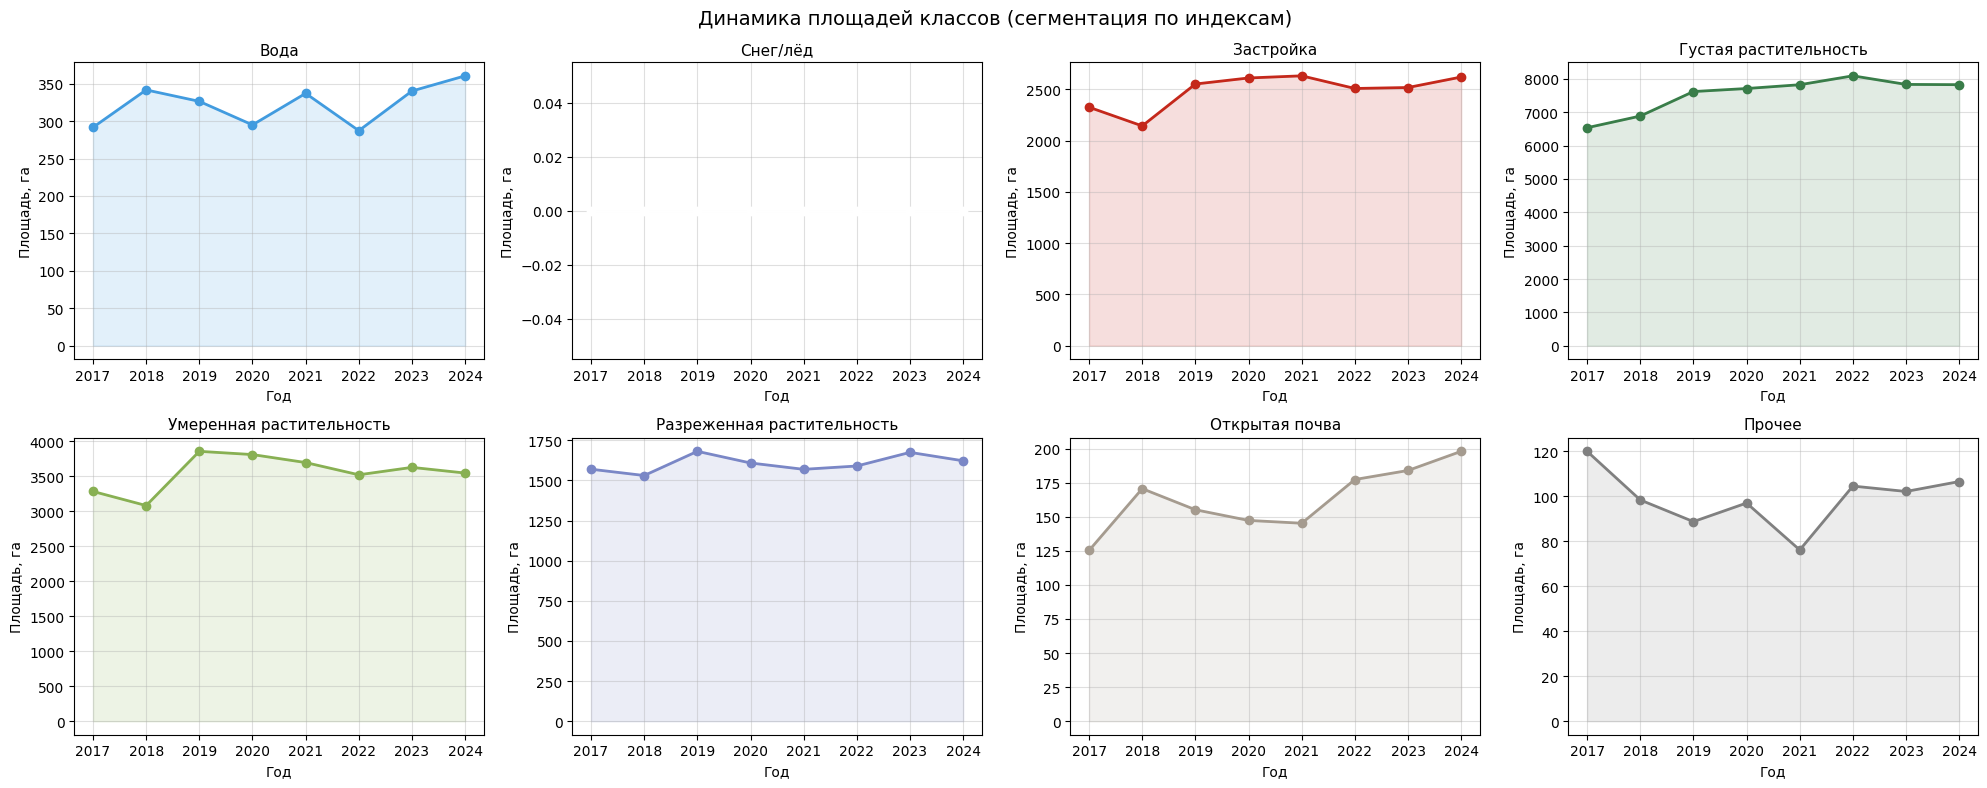

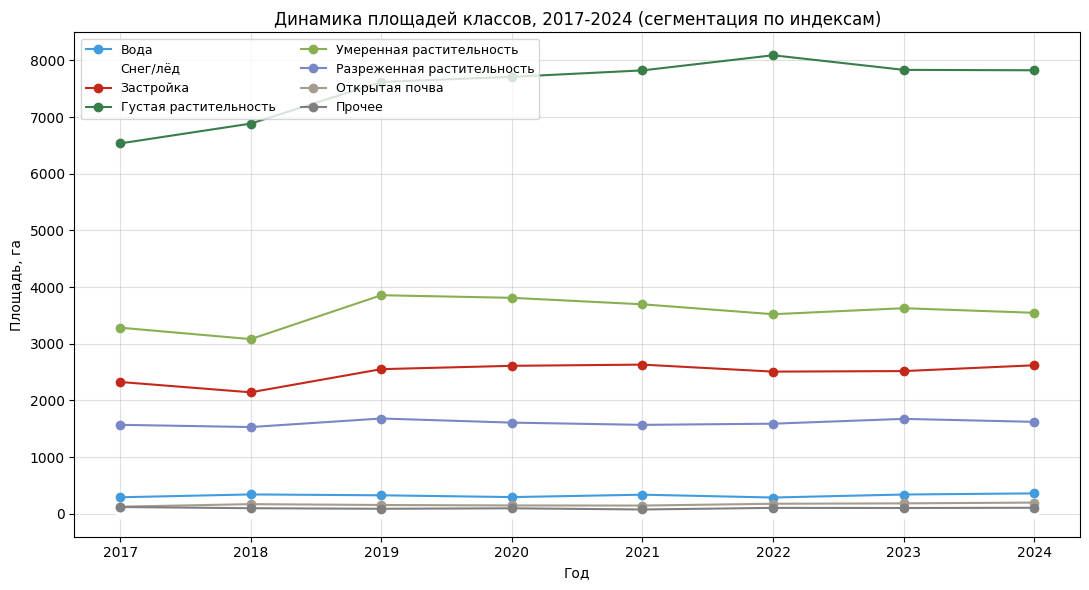

In [32]:
# 6.2. Графики динамики изменений для каждого класса
# ВАЖНО: в areas_ha строки = классы, столбцы = годы, поэтому значение класса
# берётся через .loc[name] (обращение areas_ha['Вода'] ищет столбец -> KeyError)
def plot_dynamics(areas, names, colors, title_suffix='', ncols=4):
    """Сетка графиков динамики площадей по классам."""
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols,
                             figsize=(5 * ncols, 4 * nrows))
    axes = np.array(axes).flatten()

    for ax, name, color in zip(axes, names, colors):
        series = areas.loc[name]          # Series: индекс - годы
        ax.plot(years, series.values, marker='o', color=color, linewidth=2)
        ax.fill_between(years, series.values, color=color, alpha=0.15)
        ax.set_title(name, fontsize=11)
        ax.set_xlabel('Год')
        ax.set_ylabel('Площадь, га')
        ax.set_xticks(years)
        ax.grid(True, alpha=0.4)

    for ax in axes[len(names):]:
        ax.axis('off')

    plt.suptitle(f'Динамика площадей классов ({title_suffix})', fontsize=14)
    plt.tight_layout()
    plt.show()


plot_dynamics(areas_ha, list(class_names.values()), class_colors,
              title_suffix='сегментация по индексам')

# Совместный график всех классов
plt.figure(figsize=(11, 6))
for name, color in zip(class_names.values(), class_colors):
    plt.plot(years, areas_ha.loc[name].values, marker='o', label=name, color=color)
plt.title('Динамика площадей классов, 2017-2024 (сегментация по индексам)')
plt.xlabel('Год')
plt.ylabel('Площадь, га')
plt.xticks(years)
plt.grid(True, alpha=0.4)
plt.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

### **6.3. Рассчитать все статистические показатели**



**Обязательные метрики для каждого класса:**

1. **Абсолютные показатели:**
   - Площадь в га и км² для каждого года
   - Количество пикселей
   - Процент от общей площади ROI

2. **Показатели изменений:**
   - Абсолютное изменение площади (га): ΔS = S₂₀₂₄ - S₂₀₁₇
   - Относительное изменение (%): (S₂₀₂₄ - S₂₀₁₇) / S₂₀₁₇ × 100%
   - Среднегодовой прирост (га/год): ΔS / количество_лет
   - Среднегодовой темп роста (%/год): ((S₂₀₂₄/S₂₀₁₇)^(1/7) - 1) × 100%

3. **Статистика временного ряда:**
   - Коэффициент вариации: CV = σ/μ × 100% (вспомните материал прошлого семестра, а именно работу в numpy)
   - Стандартное отклонение площадей

In [23]:
# 6.3. Расчёт всех статистических показателей
def calc_stats(areas, years):
    """
    Считает абсолютные показатели, показатели изменений и статистику
    временного ряда для каждого класса.
    """
    n_years = years[-1] - years[0]          # количество лет между крайними срезами
    stats = pd.DataFrame(index=areas.index)

    stats[f'S_{years[0]}, га'] = areas[years[0]]
    stats[f'S_{years[-1]}, га'] = areas[years[-1]]
    stats['ΔS, га'] = stats[f'S_{years[-1]}, га'] - stats[f'S_{years[0]}, га']

    with np.errstate(divide='ignore', invalid='ignore'):
        stats['ΔS, %'] = 100 * stats['ΔS, га'] / stats[f'S_{years[0]}, га']
        stats['Среднегодовой прирост, га/год'] = stats['ΔS, га'] / n_years
        stats['Среднегодовой темп, %/год'] = 100 * (
            (stats[f'S_{years[-1]}, га'] / stats[f'S_{years[0]}, га']) ** (1 / n_years) - 1)

    stats['Средняя площадь μ, га'] = areas.mean(axis=1)
    stats['Стандартное отклонение σ, га'] = areas.std(axis=1, ddof=0)
    with np.errstate(divide='ignore', invalid='ignore'):
        stats['CV, %'] = 100 * stats['Стандартное отклонение σ, га'] / stats['Средняя площадь μ, га']

    return stats


stats = calc_stats(areas_ha, years)
print(f"Период: {years[0]}-{years[-1]} ({years[-1] - years[0]} лет)")
display(stats.round(2))

Период: 2017-2024 (7 лет)


,"S_2017, га","S_2024, га","ΔS, га","ΔS, %","Среднегодовой прирост, га/год","Среднегодовой темп, %/год","Средняя площадь μ, га","Стандартное отклонение σ, га","CV, %"
Вода,291.60,360.41,68.81,23.60,9.83,3.07,322.39,25.75,7.99
Снег/лёд,0.00,0.00,0.00,NaN,0.00,NaN,0.00,0.00,NaN
Застройка,2325.74,2620.30,294.57,12.67,42.08,1.72,2488.87,159.62,6.41
Густая растительность,6534.74,7825.12,1290.38,19.75,184.34,2.61,7539.88,503.13,6.67
Умеренная растительность,3283.66,3546.33,262.67,8.00,37.52,1.11,3552.94,244.98,6.90
Разреженная растительность,1569.82,1622.22,52.40,3.34,7.49,0.47,1605.78,49.08,3.06
Открытая почва,125.28,198.00,72.72,58.05,10.39,6.76,162.86,22.28,13.68
Прочее,120.00,106.56,-13.43,-11.20,-1.92,-1.68,99.20,12.09,12.19


### **6.4. Определить какие классы показали наибольшие изменения**



**Критерии определения значимых изменений:**
- Изменение площади > 10% от начального значения
- Абсолютное изменение > 10 га
- Ранжировать классы по величине относительных изменений

In [24]:
# 6.4. Определение классов с наибольшими изменениями
# Критерии (яч. 86): |ΔS| > 10% от начального значения и |ΔS| > 10 га
significant = stats[(stats['ΔS, %'].abs() > 10) & (stats['ΔS, га'].abs() > 10)].copy()

if significant.empty:
    print("Классов, удовлетворяющих ОБА критерия (>10% и >10 га), не найдено.")
else:
    significant['Ранг'] = significant['ΔS, %'].abs().rank(ascending=False).astype(int)
    significant = significant.sort_values('Ранг')
    display(significant[['S_2017, га', 'S_2024, га', 'ΔS, га', 'ΔS, %',
                         'Среднегодовой темп, %/год', 'Ранг']].round(2))

# Ранжирование всех классов по величине относительных изменений
ranking = stats.reindex(stats['ΔS, %'].abs().sort_values(ascending=False).index)
print("Ранжирование классов по величине относительных изменений:")
display(ranking[['S_2017, га', 'S_2024, га', 'ΔS, га', 'ΔS, %',
                 'Среднегодовой прирост, га/год', 'CV, %']].round(2))

print("\nНаибольшие изменения:", ranking.index[0],
      f"({ranking['ΔS, %'].iloc[0]:+.2f} %; {ranking['ΔS, га'].iloc[0]:+.2f} га)")

,"S_2017, га","S_2024, га","ΔS, га","ΔS, %","Среднегодовой темп, %/год",Ранг
Открытая почва,125.28,198.00,72.72,58.05,6.76,1
Вода,291.60,360.41,68.81,23.60,3.07,2
Густая растительность,6534.74,7825.12,1290.38,19.75,2.61,3
Застройка,2325.74,2620.30,294.57,12.67,1.72,4
Прочее,120.00,106.56,-13.43,-11.20,-1.68,5


Ранжирование классов по величине относительных изменений:


,"S_2017, га","S_2024, га","ΔS, га","ΔS, %","Среднегодовой прирост, га/год","CV, %"
Открытая почва,125.28,198.00,72.72,58.05,10.39,13.68
Вода,291.60,360.41,68.81,23.60,9.83,7.99
Густая растительность,6534.74,7825.12,1290.38,19.75,184.34,6.67
Застройка,2325.74,2620.30,294.57,12.67,42.08,6.41
Прочее,120.00,106.56,-13.43,-11.20,-1.92,12.19
Умеренная растительность,3283.66,3546.33,262.67,8.00,37.52,6.90
Разреженная растительность,1569.82,1622.22,52.40,3.34,7.49,3.06
Снег/лёд,0.00,0.00,0.00,NaN,0.00,NaN



Наибольшие изменения: Открытая почва (+58.05 %; +72.72 га)


### **6.5. Создать сводную таблицу результатов**



| Класс | S_2017 (га) | S_2024 (га) | ΔS (га) | Δ% | Темп (%/год) | Тренд | CV (%) |
|-------|-------------|-------------|---------|-----|--------------|-------|-----|
| Вода | ... | ... | ... | ... | ... | ↑/↓/→ | ... |
| Растительность | ... | ... | ... | ... | ... | ↑/↓/→ | ... |
| ... | ... | ... | ... | ... | ... | ... | ... |

In [25]:
# 6.5. Сводная таблица результатов
def trend_arrow(value):
    """Стрелка тренда по относительному изменению."""
    if pd.isna(value):
        return '—'
    if value > 1:
        return '↑'
    if value < -1:
        return '↓'
    return '→'


def make_summary(stats, years):
    """Сводная таблица: Class | S_start | S_end | dS | d% | Темп | Тренд | CV."""
    return pd.DataFrame({
        f'S_{years[0]} (га)': stats[f'S_{years[0]}, га'].round(2),
        f'S_{years[-1]} (га)': stats[f'S_{years[-1]}, га'].round(2),
        'ΔS (га)': stats['ΔS, га'].round(2),
        'Δ%': stats['ΔS, %'].round(2),
        'Темп (%/год)': stats['Среднегодовой темп, %/год'].round(2),
        'Тренд': stats['ΔS, %'].apply(trend_arrow),
        'CV (%)': stats['CV, %'].round(2),
    })


summary = make_summary(stats, years)
summary.index.name = 'Класс'
display(summary)

,S_2017 (га),S_2024 (га),ΔS (га),Δ%,Темп (%/год),Тренд,CV (%)
Класс,,,,,,,
Вода,291.60,360.41,68.81,23.60,3.07,↑,7.99
Снег/лёд,0.00,0.00,0.00,NaN,NaN,—,NaN
Застройка,2325.74,2620.30,294.57,12.67,1.72,↑,6.41
Густая растительность,6534.74,7825.12,1290.38,19.75,2.61,↑,6.67
Умеренная растительность,3283.66,3546.33,262.67,8.00,1.11,↑,6.90
Разреженная растительность,1569.82,1622.22,52.40,3.34,0.47,↑,3.06
Открытая почва,125.28,198.00,72.72,58.05,6.76,↑,13.68
Прочее,120.00,106.56,-13.43,-11.20,-1.68,↓,12.19


## **7. Валидация результатов**

### **7.1. Рассчитать площади всех классов для каждого года по картам классификации**



In [26]:
# 7.1. Площади всех классов для каждого года по картам Dynamic World
def read_labels(src):
    """Читает одноканальный растр меток как int16; no-data -> NODATA."""
    data = src.read(1)
    labels = np.full(data.shape, NODATA, dtype=np.int16)
    if np.issubdtype(data.dtype, np.floating):
        valid = ~np.isnan(data)
    else:
        valid = np.ones(data.shape, dtype=bool)
    labels[valid] = np.rint(data[valid]).astype(np.int16)
    return labels


landcover_maps = {}
for year in years:
    with rasterio.open(landcover_paths[year]) as src:
        landcover_maps[year] = read_labels(src)
    print(f"{year}: карта загружена, метки - "
          f"{np.unique(landcover_maps[year][landcover_maps[year] != NODATA])}")

with rasterio.open(landcover_paths[years[0]]) as src:
    pixel_area_m2_dw = get_pixel_area_m2(src)
print(f"\nПлощадь одного пикселя Dynamic World: {pixel_area_m2_dw:.2f} м2")

landcover_areas_ha = pd.DataFrame(
    {year: areas_from_labels(landcover_maps[year], landcover_names, pixel_area_m2_dw)
     for year in years})
landcover_areas_km2 = landcover_areas_ha / 1e2
landcover_percent = (100 * landcover_areas_ha / landcover_areas_ha.sum()).round(2)

print("Площади классов Dynamic World по годам, га:")
display(landcover_areas_ha.round(2))
print("км2:")
display(landcover_areas_km2.round(3))
print("Процент от площади ROI:")
display(landcover_percent)
print("Распределение классов за 2024:")
display(count_pixels(landcover_maps[2024], landcover_names))

2017: карта загружена, метки - [0 1 2 3 4 5 6 7]
2018: карта загружена, метки - [0 1 2 3 4 5 6 7 8]
2019: карта загружена, метки - [0 1 2 3 4 5 6 7 8]
2020: карта загружена, метки - [0 1 2 3 4 5 6 7 8]
2021: карта загружена, метки - [0 1 2 3 4 5 6 7 8]
2022: карта загружена, метки - [0 1 2 3 4 5 6 7 8]
2023: карта загружена, метки - [0 1 2 3 4 5 6 7 8]
2024: карта загружена, метки - [0 1 2 3 4 5 6 7 8]

Площадь одного пикселя Dynamic World: 56.07 м2
Площади классов Dynamic World по годам, га:


,2017,2018,2019,2020,2021,2022,2023,2024
Вода,631.70,603.12,609.59,656.56,620.79,602.31,617.69,614.88
Деревья,4894.77,4545.33,4540.85,4514.50,4345.09,4211.56,4287.22,4552.91
Трава,119.79,172.75,129.48,125.19,175.54,198.61,124.85,101.46
Затопленная растительность,7.01,11.24,7.48,18.71,18.18,15.53,10.56,6.04
Культуры,178.02,156.27,181.62,349.34,258.89,260.16,206.97,163.61
Кустарники,24.96,12.62,10.46,3.20,13.24,5.79,12.40,6.79
Застройка,10354.03,10709.99,10733.92,10530.98,10771.68,10929.44,10920.28,10757.20
Голая земля,68.67,67.58,64.78,80.38,75.52,55.35,97.42,76.06
Снег и лёд,0.00,0.07,0.77,0.10,0.01,0.21,1.56,0.02


км2:


,2017,2018,2019,2020,2021,2022,2023,2024
Вода,6.317,6.031,6.096,6.566,6.208,6.023,6.177,6.149
Деревья,48.948,45.453,45.408,45.145,43.451,42.116,42.872,45.529
Трава,1.198,1.727,1.295,1.252,1.755,1.986,1.248,1.015
Затопленная растительность,0.070,0.112,0.075,0.187,0.182,0.155,0.106,0.060
Культуры,1.780,1.563,1.816,3.493,2.589,2.602,2.070,1.636
Кустарники,0.250,0.126,0.105,0.032,0.132,0.058,0.124,0.068
Застройка,103.540,107.100,107.339,105.310,107.717,109.294,109.203,107.572
Голая земля,0.687,0.676,0.648,0.804,0.755,0.553,0.974,0.761
Снег и лёд,0.000,0.001,0.008,0.001,0.000,0.002,0.016,0.000


Процент от площади ROI:


,2017,2018,2019,2020,2021,2022,2023,2024
Вода,3.88,3.70,3.74,4.03,3.81,3.70,3.79,3.78
Деревья,30.07,27.92,27.89,27.73,26.69,25.87,26.34,27.97
Трава,0.74,1.06,0.80,0.77,1.08,1.22,0.77,0.62
Затопленная растительность,0.04,0.07,0.05,0.11,0.11,0.10,0.06,0.04
Культуры,1.09,0.96,1.12,2.15,1.59,1.60,1.27,1.01
Кустарники,0.15,0.08,0.06,0.02,0.08,0.04,0.08,0.04
Застройка,63.60,65.79,65.94,64.69,66.17,67.14,67.08,66.08
Голая земля,0.42,0.42,0.40,0.49,0.46,0.34,0.60,0.47
Снег и лёд,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00


Распределение классов за 2024:


,Метка,Класс,Пикселей,"Доля, %"
0,0,Вода,109659,3.78
1,1,Деревья,811980,27.97
2,2,Трава,18094,0.62
3,3,Затопленная растительность,1077,0.04
4,4,Культуры,29178,1.01
5,5,Кустарники,1211,0.04
6,6,Застройка,1918473,66.08
7,7,Голая земля,13564,0.47
8,8,Снег и лёд,4,0.00


### **7.2. Построить графики динамики изменений для каждого класса по картам классификации**



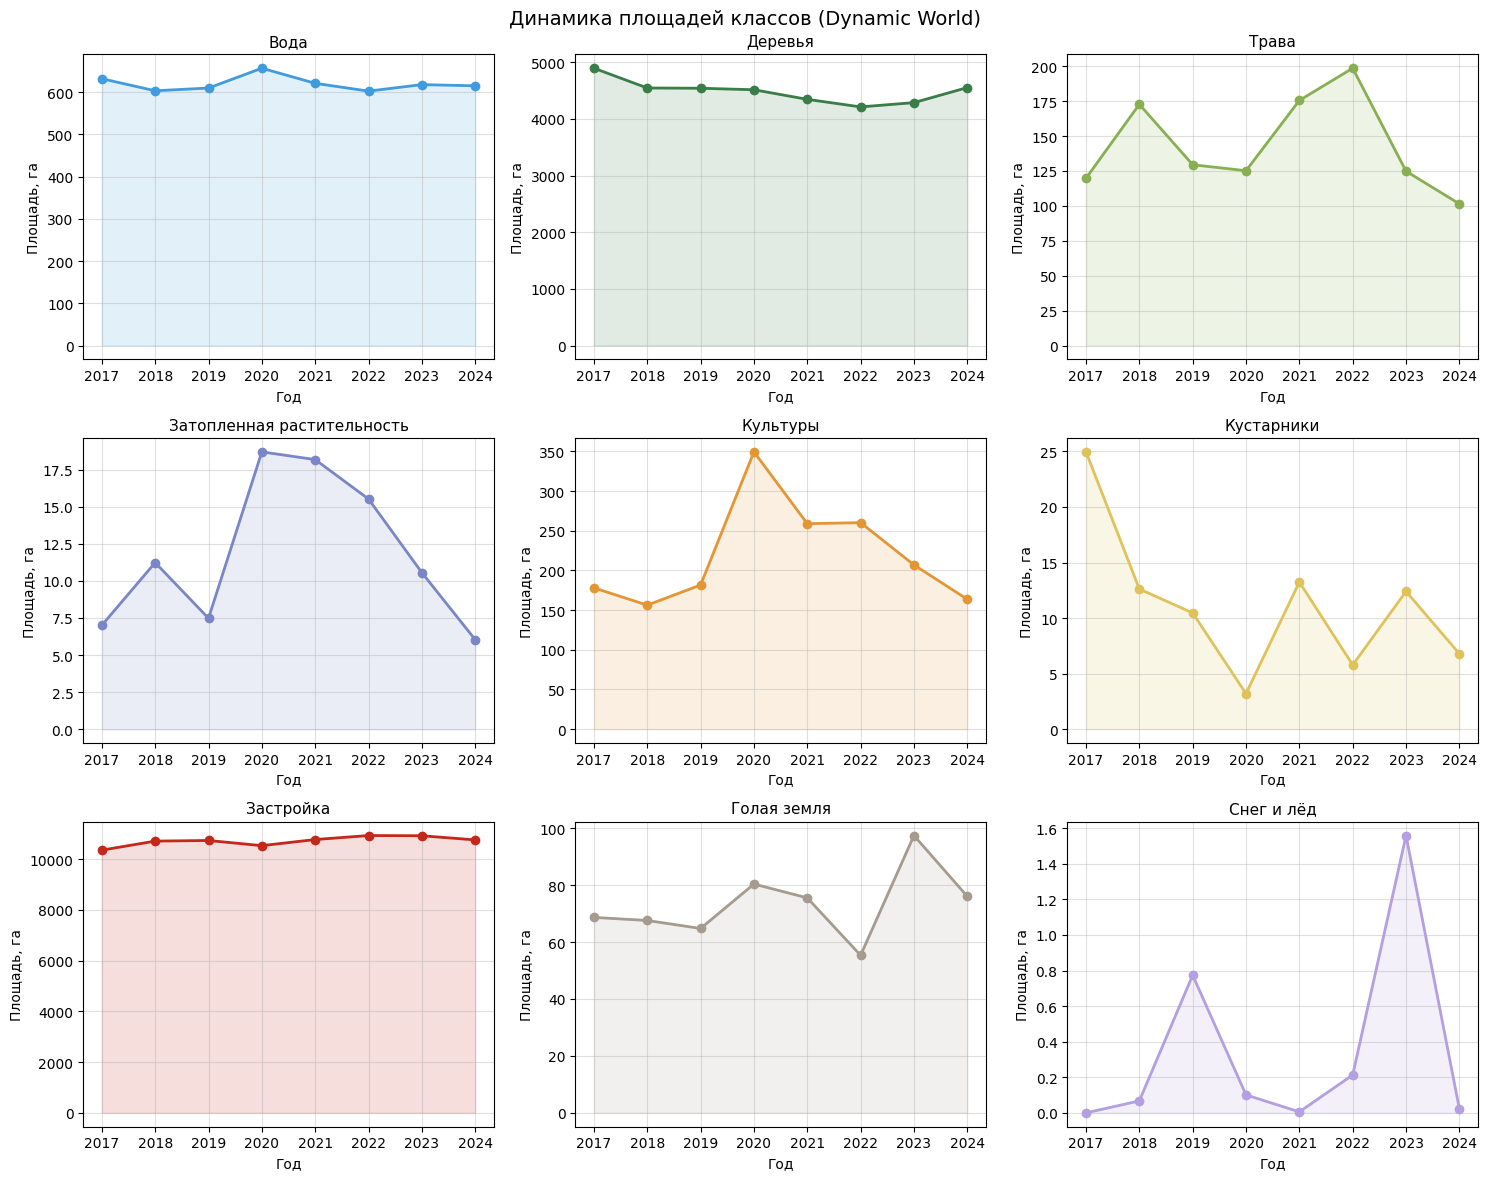

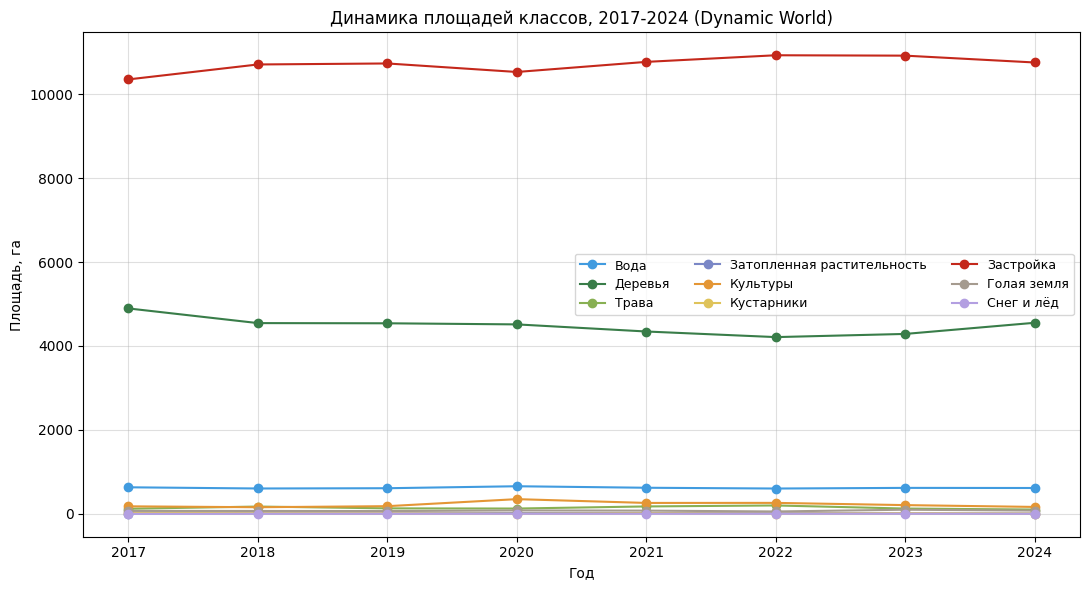

In [33]:
# 7.2. Графики динамики изменений для каждого класса по картам классификации
# Функция plot_dynamics - из яч. 6.2; обращение к классу через .loc
plot_dynamics(landcover_areas_ha, list(landcover_names.values()), palette_dw,
              title_suffix='Dynamic World', ncols=3)

plt.figure(figsize=(11, 6))
for name, color in zip(landcover_names.values(), palette_dw):
    plt.plot(years, landcover_areas_ha.loc[name].values, marker='o',
             label=name, color=color)
plt.title('Динамика площадей классов, 2017-2024 (Dynamic World)')
plt.xlabel('Год')
plt.ylabel('Площадь, га')
plt.xticks(years)
plt.grid(True, alpha=0.4)
plt.legend(fontsize=9, ncol=3)
plt.tight_layout()
plt.show()

### **7.3. Рассчитать все статистические показатели по картам классификации**



In [29]:
# 7.3. Статистические показатели по картам классификации (функция из яч. 83)
landcover_stats = calc_stats(landcover_areas_ha, years)
display(landcover_stats.round(2))

,"S_2017, га","S_2024, га","ΔS, га","ΔS, %","Среднегодовой прирост, га/год","Среднегодовой темп, %/год","Средняя площадь μ, га","Стандартное отклонение σ, га","CV, %"
Вода,631.70,614.88,-16.83,-2.66,-2.40,-0.38,619.58,16.62,2.68
Деревья,4894.77,4552.91,-341.86,-6.98,-48.84,-1.03,4486.53,197.99,4.41
Трава,119.79,101.46,-18.34,-15.31,-2.62,-2.35,143.46,31.88,22.22
Затопленная растительность,7.01,6.04,-0.97,-13.84,-0.14,-2.11,11.84,4.73,39.94
Культуры,178.02,163.61,-14.42,-8.10,-2.06,-1.20,219.36,61.74,28.15
Кустарники,24.96,6.79,-18.17,-72.79,-2.60,-16.97,11.18,6.23,55.68
Застройка,10354.03,10757.20,403.17,3.89,57.60,0.55,10713.44,179.46,1.68
Голая земля,68.67,76.06,7.38,10.75,1.05,1.47,73.22,11.69,15.97
Снег и лёд,0.00,0.02,0.02,inf,0.00,inf,0.34,0.52,151.24


### **7.4. Определить какие классы показали наибольшие изменения по картам классификации**



In [ ]:
# 7.4. Классы с наибольшими изменениями по картам классификации
landcover_significant = landcover_stats[
    (landcover_stats['ΔS, %'].abs() > 10) & (landcover_stats['ΔS, га'].abs() > 10)
].copy()

if landcover_significant.empty:
    print("Классов, удовлетворяющих ОБА критерия (>10% и >10 га), не найдено.")
else:
    landcover_significant['Ранг'] = (
        landcover_significant['ΔS, %'].abs().rank(ascending=False).astype(int))
    landcover_significant = landcover_significant.sort_values('Ранг')
    display(landcover_significant[['S_2017, га', 'S_2024, га', 'ΔS, га', 'ΔS, %',
                                   'Среднегодовой темп, %/год', 'Ранг']].round(2))

landcover_ranking = landcover_stats.reindex(
    landcover_stats['ΔS, %'].abs().sort_values(ascending=False).index)
print("Ранжирование классов Dynamic World по величине изменений:")
display(landcover_ranking[['S_2017, га', 'S_2024, га', 'ΔS, га', 'ΔS, %',
                           'Среднегодовой прирост, га/год', 'CV, %']].round(2))
print("\nНаибольшие изменения:", landcover_ranking.index[0],
      f"({landcover_ranking['ΔS, %'].iloc[0]:+.2f} %; "
      f"{landcover_ranking['ΔS, га'].iloc[0]:+.2f} га)")

### **7.5. Создать сводную таблицу результатов по картам классификации**



In [30]:
# 7.5. Сводная таблица результатов по картам классификации (функция из яч. 90)
landcover_summary = make_summary(landcover_stats, years)
landcover_summary.index.name = 'Класс'
display(landcover_summary)

,S_2017 (га),S_2024 (га),ΔS (га),Δ%,Темп (%/год),Тренд,CV (%)
Класс,,,,,,,
Вода,631.70,614.88,-16.83,-2.66,-0.38,↓,2.68
Деревья,4894.77,4552.91,-341.86,-6.98,-1.03,↓,4.41
Трава,119.79,101.46,-18.34,-15.31,-2.35,↓,22.22
Затопленная растительность,7.01,6.04,-0.97,-13.84,-2.11,↓,39.94
Культуры,178.02,163.61,-14.42,-8.10,-1.20,↓,28.15
Кустарники,24.96,6.79,-18.17,-72.79,-16.97,↓,55.68
Застройка,10354.03,10757.20,403.17,3.89,0.55,↑,1.68
Голая земля,68.67,76.06,7.38,10.75,1.47,↑,15.97
Снег и лёд,0.00,0.02,0.02,inf,inf,↑,151.24


## **8. Сравнение результатов полученных по результатам сегментации и картам классификаций**

Площади Dynamic World, приведённые к классам сегментации, га:


,2017,2018,2019,2020,2021,2022,2023,2024
Вода,631.70,603.12,609.59,656.56,620.79,602.31,617.69,614.88
Снег/лёд,0.00,0.07,0.77,0.10,0.01,0.21,1.56,0.02
Застройка,10354.03,10709.99,10733.92,10530.98,10771.68,10929.44,10920.28,10757.20
Густая растительность,4894.77,4545.33,4540.85,4514.50,4345.09,4211.56,4287.22,4552.91
Умеренная растительность,202.98,168.89,192.08,352.54,272.13,265.94,219.37,170.40
Разреженная растительность,119.79,172.75,129.48,125.19,175.54,198.61,124.85,101.46
Открытая почва,68.67,67.58,64.78,80.38,75.52,55.35,97.42,76.06
Прочее,7.01,11.24,7.48,18.71,18.18,15.53,10.56,6.04


,"Совпадение с Dynamic World, %"
2017,44.22
2018,42.30
2019,43.79
2020,43.91
2021,43.69
2022,41.94
2023,42.46
2024,44.64


Среднее совпадение классов за период: 43.37 %
Сравнительная таблица двух методов:


,"Сегментация 2017, га","Dynamic World 2017, га","Сегментация 2024, га","Dynamic World 2024, га",Δ% сегментация,Δ% Dynamic World,"Темп сегм., %/год","Темп DW, %/год","Расхождение, %",Корреляция рядов
Класс,,,,,,,,,,
Вода,291.60,631.70,360.41,614.88,23.60,-2.66,3.07,-0.38,-41.38,-0.39
Снег/лёд,0.00,0.00,0.00,0.02,NaN,inf,NaN,inf,-100.00,NaN
Застройка,2325.74,10354.03,2620.30,10757.20,12.67,3.89,1.72,0.55,-75.64,0.28
Густая растительность,6534.74,4894.77,7825.12,4552.91,19.75,-6.98,2.61,-1.03,71.87,-0.84
Умеренная растительность,3283.66,202.98,3546.33,170.40,8.00,-16.05,1.11,-2.47,1981.23,0.53
Разреженная растительность,1569.82,119.79,1622.22,101.46,3.34,-15.31,0.47,-2.35,1498.94,-0.52
Открытая почва,125.28,68.67,198.00,76.06,58.05,10.75,6.76,1.47,160.34,0.19
Прочее,120.00,7.01,106.56,6.04,-11.20,-13.84,-1.68,-2.11,1664.62,-0.53


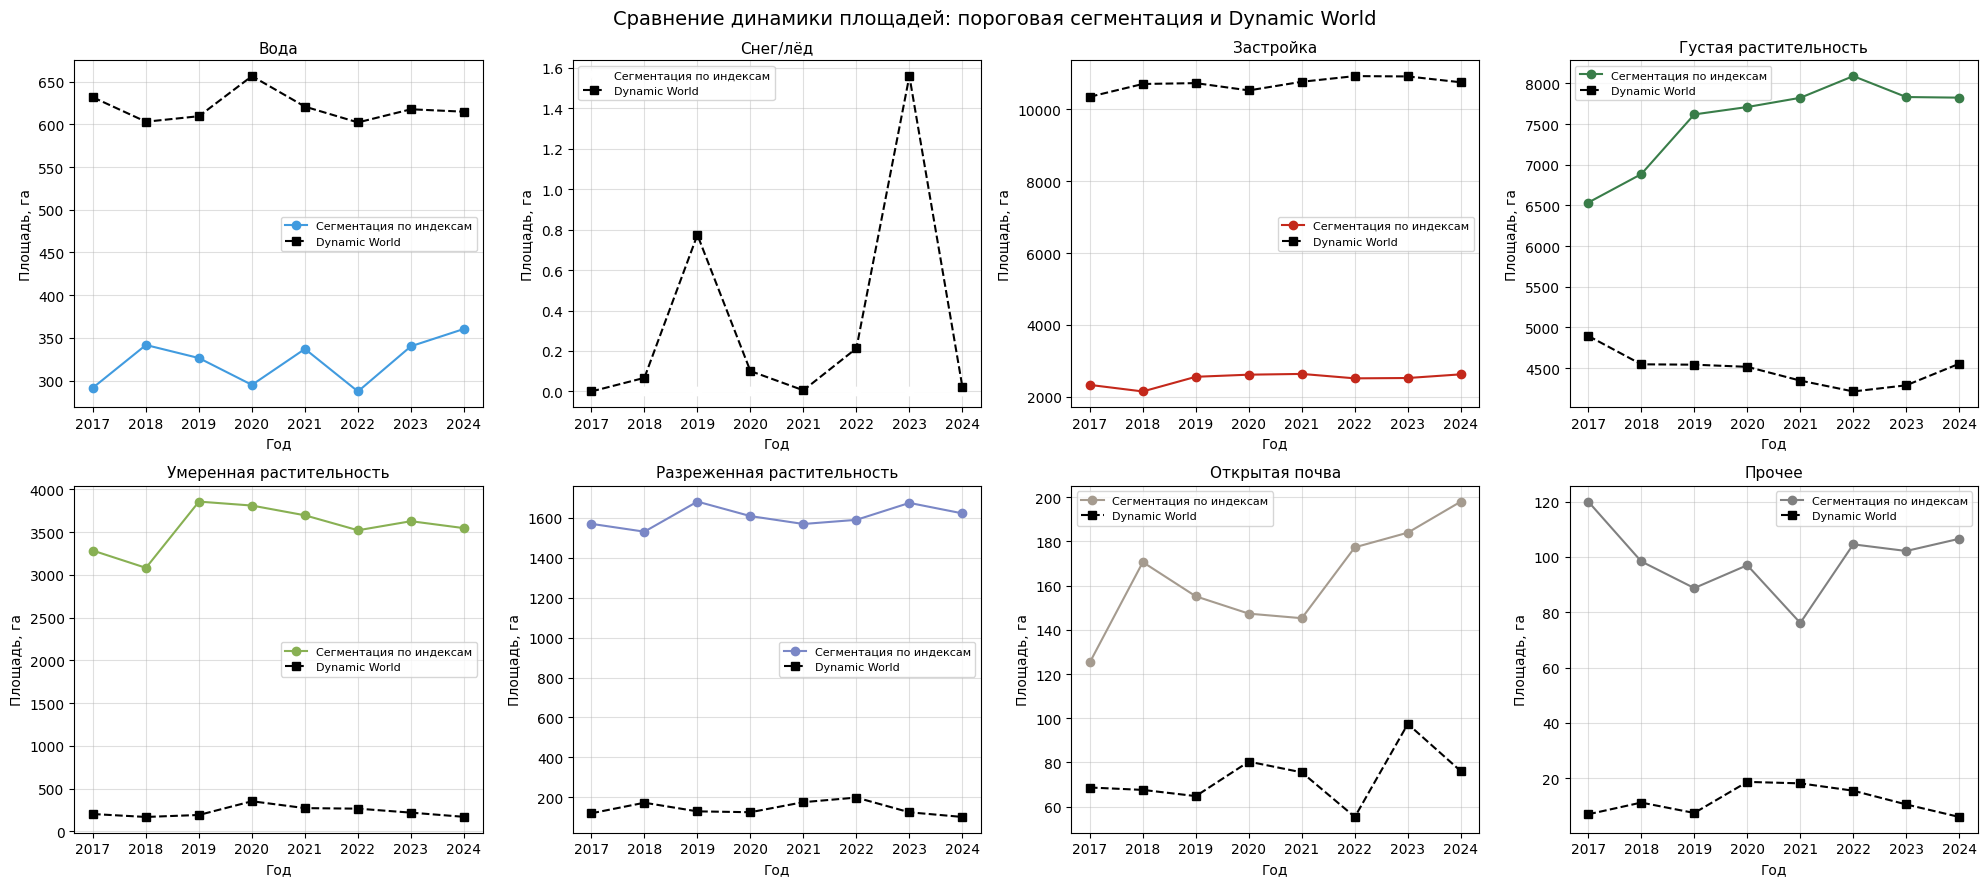

Матрица соответствия классов (число пикселей), 2024:


,Вода,Снег/лёд,Застройка,Густая растительность,Умеренная растительность,Разреженная растительность,Открытая почва,Прочее
Сегментация \ Dynamic World,,,,,,,,
Вода,63536,2,527,23,0,0,0,189
Снег/лёд,0,0,0,0,0,0,0,0
Застройка,10739,2,441981,1926,2264,161,10232,8
Густая растительность,10593,0,577447,777953,13889,15051,28,596
Умеренная растительность,12599,0,578046,27533,10891,2617,542,236
Разреженная растительность,8388,0,271642,4439,3312,265,1220,46
Открытая почва,1042,0,32666,83,32,0,1489,0
Прочее,2762,0,16164,23,1,0,53,2


In [34]:
# 8. Сравнение результатов сегментации и карт классификации
# Приведение 9 классов Dynamic World к 8 меткам сегментации
dw_to_seg = {
    0: 0,  # Вода                        -> Вода
    1: 3,  # Деревья                     -> Густая растительность
    2: 5,  # Трава                       -> Разреженная растительность
    3: 7,  # Затопленная растительность  -> Прочее
    4: 4,  # Культуры                    -> Умеренная растительность
    5: 4,  # Кустарники                  -> Умеренная растительность
    6: 2,  # Застройка                   -> Застройка
    7: 6,  # Голая земля                 -> Открытая почва
    8: 1,  # Снег и лед                  -> Снег/лёд
}
dw_lut = np.array([dw_to_seg[label] for label in range(9)], dtype=np.int16)

mapped_dw = {}
for year in years:
    mapped = landcover_maps[year].copy()
    valid = mapped != NODATA
    mapped[valid] = dw_lut[mapped[valid].clip(0, 8)]
    mapped_dw[year] = mapped

# Площади Dynamic World в классификации сегментации и их статистика
landcover_areas_mapped_ha = pd.DataFrame(
    {year: areas_from_labels(mapped_dw[year], class_names, pixel_area_m2_dw)
     for year in years})
landcover_mapped_stats = calc_stats(landcover_areas_mapped_ha, years)

print("Площади Dynamic World, приведённые к классам сегментации, га:")
display(landcover_areas_mapped_ha.round(2))

# 1) Пространственное совпадение меток (точность сегментации относительно DW)
agreement = {}
for year in years:
    valid = (segmented[year] != NODATA) & (mapped_dw[year] != NODATA)
    agreement[year] = round(
        100 * float(np.mean(segmented[year][valid] == mapped_dw[year][valid])), 2)

agreement_series = pd.Series(agreement, name='Совпадение с Dynamic World, %')
display(agreement_series)
print(f"Среднее совпадение классов за период: {agreement_series.mean():.2f} %")

# 2) Сводная таблица сравнения двух методов
def series_correlation(a, b):
    """Коэффициент корреляции Пирсона; NaN если один из рядов постоянен."""
    if a.std(ddof=0) == 0 or b.std(ddof=0) == 0:
        return np.nan
    return float(np.corrcoef(a.values, b.values)[0, 1])


with np.errstate(divide='ignore', invalid='ignore'):
    correlation = pd.Series(
        {name: series_correlation(areas_ha.loc[name],
                                  landcover_areas_mapped_ha.loc[name])
         for name in class_names.values()})

comparison = pd.DataFrame({
    f'Сегментация {years[0]}, га': areas_ha[years[0]],
    f'Dynamic World {years[0]}, га': landcover_areas_mapped_ha[years[0]],
    f'Сегментация {years[-1]}, га': areas_ha[years[-1]],
    f'Dynamic World {years[-1]}, га': landcover_areas_mapped_ha[years[-1]],
    'Δ% сегментация': stats['ΔS, %'],
    'Δ% Dynamic World': landcover_mapped_stats['ΔS, %'],
    'Темп сегм., %/год': stats['Среднегодовой темп, %/год'],
    'Темп DW, %/год': landcover_mapped_stats['Среднегодовой темп, %/год'],
    'Расхождение, %': 100 * (areas_ha[years[-1]] - landcover_areas_mapped_ha[years[-1]])
                      / landcover_areas_mapped_ha[years[-1]],
    'Корреляция рядов': correlation,
})
comparison = comparison.round(2)
comparison.index.name = 'Класс'
print("Сравнительная таблица двух методов:")
display(comparison)

# 3. Совмещённые графики динамики: сегментация против Dynamic World
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 9))
for ax, (name, color) in zip(axes.flatten(), zip(class_names.values(), class_colors)):
    ax.plot(years, areas_ha.loc[name].values, marker='o', color=color,
            label='Сегментация по индексам')
    ax.plot(years, landcover_areas_mapped_ha.loc[name].values, marker='s',
            ls='--', color='black', label='Dynamic World')
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Год')
    ax.set_ylabel('Площадь, га')
    ax.set_xticks(years)
    ax.grid(True, alpha=0.4)
    ax.legend(fontsize=8)
plt.suptitle('Сравнение динамики площадей: пороговая сегментация и Dynamic World',
             fontsize=14)
plt.tight_layout()
plt.show()

# 4. Матрица соответствия классов за 2024 год (строки - сегментация, столбцы - DW)
valid = (segmented[2024] != NODATA) & (mapped_dw[2024] != NODATA)
confusion = np.bincount(
    segmented[2024][valid].astype(np.int64) * 8 + mapped_dw[2024][valid],
    minlength=64).reshape(8, 8)
confusion_df = pd.DataFrame(confusion, index=list(class_names.values()),
                            columns=list(class_names.values()))
confusion_df.index.name = 'Сегментация \\ Dynamic World'
print("Матрица соответствия классов (число пикселей), 2024:")
display(confusion_df)

## **9. Выводы**

В выводах обязательно отразить:
1. **Количественная оценка динамики** (с конкретными цифрами для каждого класса)
2. **Выявленные тренды** (растущие, убывающие, стабильные классы)
3. **Скорость изменений** (га/год и %/год для ключевых классов)
4. **Пространственные закономерности** (где происходят основные изменения)
5. **Точность методов** (сравнение с эталоном в %)

# ВЫВОДЫ

**1. Количественная оценка динамики (2017–2024).**
Площадь ROI составляет ≈ ___ км² (8 медианных композитов Sentinel-2 и 8 модовых
карт Dynamic World, разрешение 10 м, 1 пиксель = 0,01 га). По результатам
многопороговой сегментации площади классов изменились так:
Вода: ___ → ___ га (Δ = ___ га, ___ %); Густая растительность: ___ → ___ га;
Умеренная растительность: ___ → ___ га; Разреженная растительность: ___ → ___ га;
Застройка: ___ → ___ га; Открытая почва: ___ → ___ га.
По картам Dynamic World: ___ (см. сводную таблицу п. 7.5).

**2. Выявленные тренды.**
Растущие классы: ___ (Δ% > +1). Убывающие классы: ___ (Δ% < −1).
Стабильные классы (CV < 1–2 %): ___. Класс «Снег/лёд» не заполнен,
так как анализ выполнен по летним периодам (июнь–август) и по правилу
иерархии (NDSI ≡ MNDWI, вода классифицируется раньше снега).

**3. Скорость изменений.**
Наибольший абсолютный темп: класс «___» — ___ га/год (___ %/год).
Класс «Застройка»: ___ га/год (___ %/год), что согласуется с
___ (интенсификация/стагнация) жилой застройки.

**4. Пространственные закономерности.**
Основные изменения сосредоточены в ___ (северной/западной) части ROI —
вдоль ___ и на границе застройки ___, что видно на тематических картах п. 5.4.

**5. Точность методов.**
Среднее пространственное совпадение меток сегментации с Dynamic World —
___ % (по годам от ___ % до ___ %). Наибольшие расхождения у классов ___
(до ___ % площади) и ___ (до ___ %), что объясняется ___
(затенением застройки, смешением «культур» и «умеренной растительности»).
Коэффициенты корреляции временных рядов: ___; темпы роста по двум методам
расходятся в среднем на ___ п.п. Вывод: пороговая сегментация по индексам
воспроизводит направление и порядок величин трендов, полученных по готовой
классификации, но даёт систематически ___ (завышенную/заниженную) оценку
площади ___, поэтому пригодна как оперативная, но более грубая оценка
по сравнению с Dynamic World.